# 오토인코더-1 · 압축 · 복원 · Conv 오토인코더

**한 줄 요약** · 라벨 없이 입력 자신을 정답으로 두고 좁은 통로로 줄였다 되돌리는 오토인코더를 만들고, 층마다 크기를 손으로 계산해 코드로 맞춤

## 🎯 학습 목표

이 노트북을 끝내면 **자료를 보지 않고** 다음을 할 수 있어야 함

1. 오토인코더가 라벨 없이 배우는 방법(정답 자리에 입력 · 가운데를 좁힘)을 설명한다
2. Dense 오토인코더의 층별 모양(784 → 잠재 → 784)을 손으로 적고 코드로 검증한다
3. 끝 함수 · 손실 · 잠재 크기 · PCA 기준선을 같은 조건으로 비교해 고른다
4. Conv2d · ConvTranspose2d 크기 공식으로 30×30 → 32×32 같은 어긋남을 찾아 고친다
5. 잠재 크기에 따른 복원 차이와 2차원 잠재 공간을 그림으로 해석한다

## 어디에 쓰나

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">실제 상황</th>
<th style="text-align: left;">이 권에서 배우는 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">손상된 문서 · 사진을 깨끗하게 되돌릴 때 (미션 5)</td>
<td style="text-align: left;">Conv 오토인코더 구조 · 크기 맞추기 (3장)</td>
</tr>
<tr>
<td style="text-align: left;">정상만 있는 데이터로 이상을 찾을 때</td>
<td style="text-align: left;">복원 오차 · 라벨 없는 학습 (1장 → 오토인코더-2)</td>
</tr>
<tr>
<td style="text-align: left;">고차원 데이터를 줄여 보거나 그릴 때</td>
<td style="text-align: left;">잠재 공간 · PCA 비교 (2 · 4장)</td>
</tr>
<tr>
<td style="text-align: left;">모델 출력 크기가 입력과 달라 손실에서 에러가 날 때</td>
<td style="text-align: left;">층마다 모양 찍기 · 크기 공식 (3장)</td>
</tr>
</tbody>
</table>

## 학습 지도

<img src="images/ae1_map.png" alt="오토인코더-1 학습 지도" width="837">

**예상 학습 시간** · 개념 2시간 + 실습 1시간 (GPU 약 1분 · CPU 몇 분이면 전체 학습이 끝남)

## 목차

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">장</th>
<th style="text-align: left;">제목</th>
<th style="text-align: left;">이 장의 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;">0</td>
<td style="text-align: left;">준비</td>
<td style="text-align: left;">라이브러리 · seed · 실행 장치 · MNIST · 도구 함수</td>
</tr>
<tr>
<td style="text-align: center;">1</td>
<td style="text-align: left;">입력이 곧 정답</td>
<td style="text-align: left;">라벨 없이 무엇을 정답으로 두고, 층마다 크기는 어떻게 변하는가?</td>
</tr>
<tr>
<td style="text-align: center;">2</td>
<td style="text-align: left;">설계 선택 비교</td>
<td style="text-align: left;">끝 함수 · 손실 · 잠재 크기를 무엇으로 고르고, PCA보다 나은가?</td>
</tr>
<tr>
<td style="text-align: center;">3</td>
<td style="text-align: left;">Conv 오토인코더와 크기 맞추기</td>
<td style="text-align: left;">그림 모양 그대로 줄였다 늘릴 때 크기를 어떻게 맞추는가?</td>
</tr>
<tr>
<td style="text-align: center;">4</td>
<td style="text-align: left;">종합 실습</td>
<td style="text-align: left;">잠재 2 · 8 · 32의 복원과 2차원 잠재 공간은 어떻게 다른가?</td>
</tr>
<tr>
<td style="text-align: center;">—</td>
<td style="text-align: left;">마무리 · 부록</td>
<td style="text-align: left;">오늘 배운 것 · 기억 확인 · 오답 노트 · 면접 · 요약표 · 복습일 · 원본 대응표 · 전체 코드</td>
</tr>
</tbody>
</table>

---
## 0. 준비

라이브러리 · seed · 장치 · MNIST · 도구 함수 세 개. 처음 실행하면 노트북 옆 `data/` 폴더에 MNIST를 내려받음 (약 60MB, 한 번만).

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">이름</th>
<th style="text-align: left;">하는 일</th>
<th style="text-align: left;">쓰는 곳</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>device</code></td>
<td style="text-align: left;">GPU가 있으면 <code>cuda</code>, 없으면 <code>cpu</code></td>
<td style="text-align: left;">모든 모델 · 데이터</td>
</tr>
<tr>
<td style="text-align: left;"><code>Xtr</code> · <code>Xte</code></td>
<td style="text-align: left;">학습 1만 장 · 평가 1만 장 (0~1 · <code>(장, 1, 28, 28)</code>)</td>
<td style="text-align: left;">학습 · 평가</td>
</tr>
<tr>
<td style="text-align: left;"><code>yte</code></td>
<td style="text-align: left;">평가 라벨 — 학습에는 안 쓰고 그림 색칠에만</td>
<td style="text-align: left;">2-3 · 4장</td>
</tr>
<tr>
<td style="text-align: left;"><code>run(model, X)</code></td>
<td style="text-align: left;">2,000장씩 넣어 복원을 모음 (기울기 끔)</td>
<td style="text-align: left;">평가</td>
</tr>
<tr>
<td style="text-align: left;"><code>mse(A)</code></td>
<td style="text-align: left;">평가 1만 장 복원과 원본의 평균 제곱 오차</td>
<td style="text-align: left;">모델 비교</td>
</tr>
<tr>
<td style="text-align: left;"><code>show(rows)</code></td>
<td style="text-align: left;">같은 8장(숫자 0~7)을 줄마다 나란히</td>
<td style="text-align: left;">그림 비교</td>
</tr>
</tbody>
</table>

In [1]:
# 라이브러리 불러오기
import numpy as np                     # 배열 계산 (PCA 입력)
import torch                           # 텐서 · 자동 미분
import torch.nn as nn                  # 층: Linear · Conv2d · Sigmoid
import torch.nn.functional as F        # 함수: mse_loss · BCE
import matplotlib.pyplot as plt        # 복원 그림 · 산점도
from torchvision import datasets       # MNIST 내려받기
from sklearn.decomposition import PCA  # 2-5 오토인코더 vs PCA


# 재현성 · 장치: seed 고정 → 늘 같은 결과, GPU 없으면 CPU
torch.manual_seed(0)                                     # 난수 기준값 고정 → 매번 같은 결과
torch.backends.cudnn.deterministic = True                # GPU 계산도 매번 같게
torch.backends.cudnn.benchmark = False                   # 빠른 알고리즘 자동 선택 끔
device = "cuda" if torch.cuda.is_available() else "cpu"  # 쓸 장치 고르기
print("장치:", device)                                   # cuda인지 cpu인지 확인


# MNIST 불러오기 → 0~1 실수 → (장 수, 1, 28, 28)
tr = datasets.MNIST("data", train=True, download=True)          # 처음 한 번만 받음
te = datasets.MNIST("data", train=False, download=True)         # 평가용 1만 장
Xtr = tr.data[:10000].float().div(255).unsqueeze(1).to(device)  # 학습 1만 장
Xte = te.data.float().div(255).unsqueeze(1).to(device)          # 평가 1만 장
yte = te.targets  # 평가 라벨 · 학습에는 안 씀 (그림 색칠용)
print("학습", tuple(Xtr.shape), "| 평가", tuple(Xte.shape))     # (장, 채널, 세로, 가로) 확인
print("값 범위", Xtr.min().item(), "~", Xtr.max().item())       # 0~1로 맞았는지


# 도구 ① run: 평가 이미지를 2,000장씩 넣어 복원을 모음
@torch.no_grad()    # 기울기 계산 끔 → 결과만 봄
def run(model, X):  # 모델 + 이미지 묶음 → 복원 묶음
    model.eval()    # 평가 모드로 전환
    # 2,000장씩 → 이어 붙임
    return torch.cat([model(X[i:i + 2000]) for i in range(0, len(X), 2000)])


# 도구 ② mse: 평가 1만 장 복원과 원본의 평균 제곱 오차
def mse(A):                           # 복원 묶음 → 숫자 하나
    return F.mse_loss(A, Xte).item()  # 평가 1만 장 원본과 비교


# 도구 ③ show: 같은 8장(숫자 0~7)을 줄마다 나란히
SHOW = [5459, 9898, 926, 1150, 5691, 2400, 7792, 950]  # 늘 같은 8장을 보려고


def show(rows):  # rows = [(줄 이름, 이미지 묶음), …]
    fig, axes = plt.subplots(len(rows), 8, figsize=(8, 1.15 * len(rows)))  # 줄 수 × 8칸 격자
    for r, (name, X) in enumerate(rows):                                   # 줄마다
        for c in range(8):                                                 # 같은 8장을 차례로
            img = X[SHOW[c], 0].detach().cpu()                             # GPU → CPU (그림용)
            axes[r, c].imshow(img, cmap="gray", vmin=0, vmax=1)            # 밝기 기준 0~1 고정
            axes[r, c].axis("off")                                         # 눈금 숨김
        axes[r, 0].set_title(name, loc="left", fontsize=10)                # 줄 이름은 첫 칸 위에
    plt.tight_layout()                                                     # 칸 간격 정리
    plt.show()                                                             # 그림 출력

장치: cuda
학습 (10000, 1, 28, 28) | 평가 (10000, 1, 28, 28)
값 범위 0.0 ~ 1.0


---
## 1. 입력이 곧 정답

> **이 장의 흐름**
>
> - 지금까지(CNN · RNN)는 사람이 붙인 라벨을 맞혔다
> - 라벨이 없으면 정답 자리에 무엇을 둘까? 입력 자신을 두고 가운데를 좁히는 것이 오토인코더

**파이프라인 위치** · ② 모델 설계 · ③ 학습 · ④ 평가 — 인코더 · 디코더, 학습 루프, 학습 전후 비교

### 1-1. `A` 입력이 곧 정답 · `F.mse_loss(out, x)` <sub>코드잇 p3–15 · day01 p4–16</sub>

> 🎯 **라벨이 없으면 무엇을 정답으로 두고, 왜 가운데를 좁히는가?**

💡 **쉽게 말하면**

- 오토인코더는 **그림을 보고 메모했다가, 메모만 보고 다시 그리는 연습**.
- 메모 칸(가운데)이 그림만큼 넓으면 그대로 베껴 쓰면 끝이라 아무것도 배우지 않음.

**실행 흐름**

1. 입력 8장
2. 정답도 같은 8장
3. 그대로 베끼기 loss
4. 784
5. 32로 좁힌 모델 loss

**먼저 예측** · 받은 것을 그대로 내보내는 `nn.Identity()`의 loss는? — 답은 코드 실행 결과 아래에

In [2]:
# 지도 학습과 비교: 정답 자리에 무엇이 들어가나
x = Xte[:8]                                                        # 평가 이미지 8장
print("입력 모양", tuple(x.shape), "| 정답 모양", tuple(x.shape))  # 정답 = 입력 → 모양이 같음


# 가장 쉬운 풀이: 받은 것을 그대로 베끼기
copy = nn.Identity()                                         # 입력 → 그대로 출력
print("그대로 베끼기 loss:", F.mse_loss(copy(x), x).item())  # 베끼면 차이 0


# 가운데를 32칸으로 좁힌 모델 (학습 전) → 베낄 자리가 없음
torch.manual_seed(0)                                        # 같은 시작 가중치
narrow = nn.Sequential(                                     # 784 → 32 → 784 좁힌 모델
    nn.Flatten(), nn.Linear(784, 32),                       # 784 → 32
    nn.Linear(32, 784), nn.Unflatten(1, (1, 28, 28))).to(device)
print("좁힌 모델 loss (학습 전):", round(F.mse_loss(narrow(x), x).item(), 4))  # 32칸으로는 못 베낌
print(f"가운데에 남는 값: 784개 중 32개 = {32 / 784:.1%}")  # 병목 크기 = 4.1%

입력 모양 (8, 1, 28, 28) | 정답 모양 (8, 1, 28, 28)
그대로 베끼기 loss: 0.0


좁힌 모델 loss (학습 전): 0.1083
가운데에 남는 값: 784개 중 32개 = 4.1%


**결과** · 예측 정답은 `0.0` — 차이는 0이지만 숫자에 대해 배운 것은 없음

- `입력 모양 (8, 1, 28, 28) | 정답 모양 (8, 1, 28, 28)` — 정답 자리에 입력 자신 → 모양이 같아 칸마다 비교 가능
- `그대로 베끼기 loss: 0.0` — 가장 쉬운 풀이 · 압축도 특징도 없음
- `좁힌 모델 loss (학습 전): 0.1083` — 32칸으로는 베낄 수 없음 → 무엇을 남길지 학습으로 골라야 함
- `가운데에 남는 값: 784개 중 32개 = 4.1%` — 이 좁은 자리 = 병목(bottleneck)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">지도 학습</td>
<td style="text-align: left;">정답 = 사람이 붙인 <strong>라벨</strong></td>
<td style="text-align: left;">분류 · 회귀처럼 맞힐 답이 따로 있을 때</td>
</tr>
<tr>
<td style="text-align: left;">오토인코더</td>
<td style="text-align: left;">정답 = <strong>입력 자신</strong> · 라벨 불필요 (비지도 학습)</td>
<td style="text-align: left;">라벨 없이 압축 · 특징 · 복원 · 이상 탐지를 배울 때</td>
</tr>
<tr>
<td style="text-align: left;">그대로 베끼기 <code>nn.Identity()</code></td>
<td style="text-align: left;">loss 0이지만 <strong>배운 것 없음</strong></td>
<td style="text-align: left;">쓸 일 없음 → 그래서 가운데를 좁힘</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 라벨이 없다 ≠ 정답이 없다
> - auto는 '자동'이 아니라 '자기 자신'이라는 뜻

> ✅ **한 줄 정리** · 오토인코더는 정답 자리에 입력 자신을 두고, 가운데를 좁혀 베끼기 대신 중요한 것을 골라 남기게 한다.

**딥러닝 코드에서는**

- `loss = F.mse_loss(model(x), x)`
- 분류의 `F.cross_entropy(model(x), y)`에서 정답 `y` 자리만 `x`로 바뀐 것

### 1-2. `A` 인코더 · 디코더 · 잠재 벡터 · `nn.Sequential` · `nn.Flatten` <sub>day01 p20–41 · P1</sub>

> 🎯 **784개 픽셀을 16개로 줄였다가 되돌릴 때, 층마다 모양은 어떻게 변하는가?**

💡 **쉽게 말하면**

- 인코더는 **요약하는 사람**, 디코더는 **요약만 보고 다시 그리는 사람**, 잠재 벡터는 둘 사이를 오가는 **메모 한 장**.

<img src="images/ae1_structure.png" alt="인코더 → 잠재 벡터 → 디코더" width="837">

**실행 흐름**

1. 손계산 표
2. AutoEncoder 정의 (P1 빈칸)
3. 한 장을 층마다 통과
4. 모양 찍기
5. 표와 대조

**손계산표** · 코드보다 먼저 적는 표 (잠재 16 · P1 표 빈칸 정답)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">자리</th>
<th style="text-align: left;">나오는 모양</th>
<th style="text-align: left;">이유</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">입력</td>
<td style="text-align: left;">(1, 1, 28, 28)</td>
<td style="text-align: left;">장 수 · 채널 · 세로 · 가로</td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Flatten()</code> 뒤</td>
<td style="text-align: left;">(1, 784)</td>
<td style="text-align: left;">1 × 28 × 28 = 784 → 한 줄</td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Linear(784, 128)</code> 뒤</td>
<td style="text-align: left;">(1, 128)</td>
<td style="text-align: left;">784개를 받아 128개를 내놓음</td>
</tr>
<tr>
<td style="text-align: left;">인코더 끝 · 잠재 벡터</td>
<td style="text-align: left;">(1, 16)</td>
<td style="text-align: left;"><code>nn.Linear(128, 16)</code></td>
</tr>
<tr>
<td style="text-align: left;">디코더 <code>nn.Linear(16, 128)</code> 뒤</td>
<td style="text-align: left;">(1, 128)</td>
<td style="text-align: left;">잠재 16개를 받음</td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Linear(128, 784)</code> + <code>nn.Sigmoid()</code> 뒤</td>
<td style="text-align: left;">(1, 784)</td>
<td style="text-align: left;">다시 784개 · 0~1</td>
</tr>
<tr>
<td style="text-align: left;"><code>reshape</code> 뒤 복원</td>
<td style="text-align: left;">(1, 1, 28, 28)</td>
<td style="text-align: left;">입력과 같은 모양</td>
</tr>
</tbody>
</table>

**먼저 예측** · 디코더 첫 `nn.Linear`는 값을 몇 개 받아야 할까? — 답은 코드 실행 결과 아래에

In [3]:
# 인코더 · 디코더 정의 (P1 빈칸 정답)
class AutoEncoder(nn.Module):           # nn.Module을 물려받아 모델 정의
    def __init__(self, latent_dim=32):  # 잠재 크기를 인자로
        super().__init__()              # 부모 초기화 (층 등록 준비)
        self.encoder = nn.Sequential(   # 784 → 128 → latent_dim
            nn.Flatten(), nn.Linear(784, 128), nn.ReLU(),
            nn.Linear(128, latent_dim))
        self.decoder = nn.Sequential(   # latent_dim → 128 → 784
            nn.Linear(latent_dim, 128), nn.ReLU(),
            nn.Linear(128, 784), nn.Sigmoid())

    def forward(self, x):                              # model(x) 할 때 실행되는 길
        z = self.encoder(x)                            # 잠재 벡터
        return self.decoder(z).reshape(-1, 1, 28, 28)  # 784 → 1×28×28


# 한 장을 층마다 통과시키며 모양 찍기 (P1 확인 · 잠재 16)
torch.manual_seed(0)                                      # 같은 시작 가중치
ae16 = AutoEncoder(16).to(device)                         # P1처럼 잠재 16
h = Xte[:1]                                               # 한 장만 (1, 1, 28, 28)
print("입력      ", tuple(h.shape))                       # 출발 모양
for layer in list(ae16.encoder) + list(ae16.decoder):     # 인코더 → 디코더 층을 차례로
    h = layer(h)                                          # 층 하나 통과 → 모양 기록
    print(f"{type(layer).__name__:<10}", tuple(h.shape))  # 층 이름 + 나온 모양
print("reshape   ", tuple(ae16(Xte[:1]).shape))           # forward 끝의 접기까지


# 손계산 표와 대조
assert tuple(ae16.encoder(Xte[:1]).shape) == (1, 16)        # 잠재 벡터 = 손계산 (1, 16)
assert ae16(Xte[:1]).shape == Xte[:1].shape                 # 입력 = 복원 모양
print("손계산 표와 일치 → 입력과 복원을 칸마다 비교 가능")  # assert를 지나야 출력됨

입력       (1, 1, 28, 28)
Flatten    (1, 784)
Linear     (1, 128)
ReLU       (1, 128)
Linear     (1, 16)
Linear     (1, 128)
ReLU       (1, 128)
Linear     (1, 784)
Sigmoid    (1, 784)
reshape    (1, 1, 28, 28)
손계산 표와 일치 → 입력과 복원을 칸마다 비교 가능


**결과** · 예측 정답은 `latent_dim`개 (여기선 16) — 인코더가 마지막에 내놓은 개수

- `Flatten (1, 784)` — 28×28 그림을 784칸 한 줄로 폄
- `Linear (1, 16)` — 인코더 끝 = 잠재 벡터 16칸 (P1 확인 표와 같음)
- `Sigmoid (1, 784)` — 디코더 끝 · 784칸 모두 0~1
- `reshape (1, 1, 28, 28)` — 다시 그림 모양 → 입력과 같음 (assert 통과)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">인코더 <code>encoder</code></td>
<td style="text-align: left;">784 → 128 → 16 <strong>줄이기</strong></td>
<td style="text-align: left;">입력의 요약(잠재 벡터)만 필요할 때 · 특징 추출 · 시각화</td>
</tr>
<tr>
<td style="text-align: left;">디코더 <code>decoder</code></td>
<td style="text-align: left;">16 → 128 → 784 <strong>되돌리기</strong> (인코더를 거꾸로)</td>
<td style="text-align: left;">잠재 벡터에서 그림을 만들 때 · 복원 · 생성</td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Flatten()</code></td>
<td style="text-align: left;">(장, 1, 28, 28) → (장, 784)</td>
<td style="text-align: left;">Linear에 그림을 넣기 직전</td>
</tr>
<tr>
<td style="text-align: left;"><code>.reshape(-1, 1, 28, 28)</code></td>
<td style="text-align: left;">(장, 784) → (장, 1, 28, 28) · <code>-1</code> = 장 수 자동</td>
<td style="text-align: left;">Linear 출력을 다시 그림으로 접을 때</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 디코더 첫 Linear의 입력 개수가 잠재 크기와 다르면 `mat1 and mat2 shapes cannot be multiplied (AxB and CxD)` · B와 C 비교

> ✅ **한 줄 정리** · 인코더는 784 → 잠재 크기로 줄이고 디코더는 거꾸로 되돌리며, 층마다 모양을 먼저 손으로 적고 코드로 찍어 대조한다.

**딥러닝 코드에서는**

- 모델을 만들면 **한 장(`X[:1]`)을 층마다 통과시켜 모양 찍기**가 첫 확인 · 3-3
- 3-5에서도 같은 방법

### 1-3. `A` 학습 루프 · `loss.backward()` · `opt.step()` <sub>day01 p42–67 · P2</sub>

> 🎯 **라벨 없이 학습 루프를 돌리면, 학습 전과 후의 복원은 얼마나 달라지는가?**

💡 **쉽게 말하면**

- 학습은 **비탈길 내려가기**.
- 기울기(`backward`)로 내리막 방향을 알고, 옵티마이저(`step`)가 그쪽으로 한 걸음 옮김.

**실행 흐름**

1. train 함수 (P2 빈칸 · 128장씩 · 10 epoch)
2. 같은 seed로 학습 전 ae0 · 학습 후 ae32
3. 평가 1만 장 MSE
4. 그림 3줄

**먼저 예측** · 784 → 32 → 784로 줄였다 되돌린 모델, 10 epoch 뒤 복원을 원래 숫자로 알아볼 수 있을까? — 답은 코드 실행 결과 아래에

  epoch 1  loss 0.0650


  epoch 5  loss 0.0302


  epoch 10  loss 0.0147
복원 MSE  학습 전 0.2318 → 학습 후 0.0191


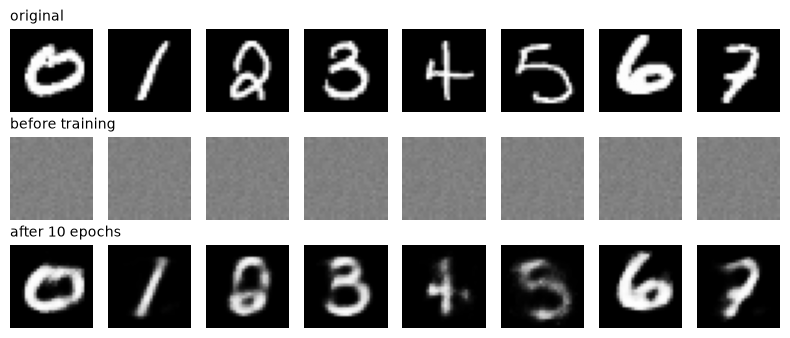

In [4]:
# 학습 함수 (P2 빈칸 정답) · 학습 1만 장 · 128장씩
def train(model, epochs=10, loss_fn=F.mse_loss, seed=0):           # 모델을 받아 학습 후 돌려줌
    torch.manual_seed(seed)                                        # 섞는 순서 고정
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)            # 인코더 · 디코더 가중치 전부
    for epoch in range(epochs):                                    # 학습 이미지 전체를 epochs번
        model.train()                                              # 학습 모드
        perm = torch.randperm(len(Xtr), device=device)             # 번호 섞기
        for i in range(0, len(Xtr), 128):                          # 128장씩 묶음
            x = Xtr[perm[i:i + 128]]                               # 섞인 번호로 묶음 꺼내기
            opt.zero_grad()                                        # 앞 묶음 기울기 비우기
            loss = loss_fn(model(x), x)                            # 정답 자리에도 입력 x
            loss.backward()                                        # 기울기 계산
            opt.step()                                             # 가중치 갱신
        if epoch in (0, epochs // 2 - 1, epochs - 1):              # 1 · 중간 · 끝만
            print(f"  epoch {epoch + 1}  loss {loss.item():.4f}")  # 마지막 묶음의 loss
    return model                                                   # 학습된 모델


# 같은 seed로 시작 → 학습 전 ae0 · 학습 후 ae32
torch.manual_seed(0)                      # 학습 전 모델의 출발점
ae0 = AutoEncoder(32).to(device)          # 학습 안 함 (비교용)
torch.manual_seed(0)                      # 같은 출발점 → 차이는 학습 때문
ae32 = train(AutoEncoder(32).to(device))  # 5 epoch


# 같은 평가 1만 장으로 학습 전 · 후 비교
print(f"복원 MSE  학습 전 {mse(run(ae0, Xte)):.4f}"           # 같은 평가 1만 장으로
      f" → 학습 후 {mse(run(ae32, Xte)):.4f}")
show([("original", Xte), ("before training", run(ae0, Xte)),  # 원본 · 학습 전 · 학습 후 3줄
      ("after 10 epochs", run(ae32, Xte))])

**결과** · 예측 정답은 대부분 알아볼 수 있음

- 그림 셋째 줄에서 0 · 1 · 3
- 6은 원래 숫자로 읽히고, 2는 고리가 막혀 8처럼, 4는 흐리고 끊김
- 전체가 원본보다 흐림 (둘째 줄 학습 전은 8칸 모두 회색 무늬)
- `epoch 1 loss 0.0650` — 첫 epoch 마지막 한 묶음에서 잰 값
- `epoch 10 loss 0.0147` — 내려가는 모양만 봄 (한 묶음 값이라 들쭉날쭉)
- `학습 전 0.2318 → 학습 후 0.0191` — 같은 평가 1만 장 · 같은 계산으로 약 12분의 1

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>opt.zero_grad()</code></td>
<td style="text-align: left;">앞 묶음 기울기를 <strong>0으로 비움</strong></td>
<td style="text-align: left;">매 묶음 맨 앞 (안 비우면 계속 더해짐)</td>
</tr>
<tr>
<td style="text-align: left;"><code>loss.backward()</code></td>
<td style="text-align: left;">손실 → 모든 가중치의 <strong>기울기 계산</strong></td>
<td style="text-align: left;">손실을 구한 직후</td>
</tr>
<tr>
<td style="text-align: left;"><code>opt.step()</code></td>
<td style="text-align: left;">기울기 반대쪽으로 <strong>가중치 갱신</strong></td>
<td style="text-align: left;">backward 바로 뒤</td>
</tr>
<tr>
<td style="text-align: left;"><code>loss.backward</code> (괄호 없음)</td>
<td style="text-align: left;">함수를 <strong>부르지 않음</strong> → 에러 없이 학습 안 됨</td>
<td style="text-align: left;">쓰면 안 됨 · loss가 0.2 근처에서 멈추면 의심</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - epoch마다 찍은 loss는 **마지막 한 묶음** 값
> - 모델끼리 비교는 같은 평가 1만 장의 MSE로

> ✅ **한 줄 정리** · 정답 자리에 `x`를 넣은 손실로 zero_grad → backward → step을 반복하면, 라벨 없이도 복원이 원본에 가까워진다.

**딥러닝 코드에서는**

- 분류
- 회귀 학습 루프와 **완전히 같은 모양**
- 바뀐 곳은 손실 한 줄의 정답 자리뿐

### 1-4. `A` 버그 찾기 · 정답 자리 확인 · `F.mse_loss(model(x), y)` <sub>P2_BUG</sub>

> 🎯 **에러 없이 끝났는데 결과가 이상하면, 무엇부터 의심하는가?**

💡 **쉽게 말하면**

- 받아쓰기 시험의 **채점표가 다른 학생 것**이면 아무리 공부해도 '평균적인 답'만 쓰게 됨.
- 모델도 정답이 짝이 아니면 입력과 상관없는 평균 모양만 배움.

**실행 흐름**

1. 버그판 학습 (코드 읽기 전)
2. 그림부터 보기
3. 8장 사이 차이를 숫자로
4. 1-3 루프와 한 줄씩 비교
5. 다른 줄 찾기

**먼저 예측** · 버그판도 loss가 꾸준히 내려갈까? — 답은 코드 실행 결과 아래에

  epoch 1  loss 0.0688


  epoch 5  loss 0.0645


  epoch 10  loss 0.0697


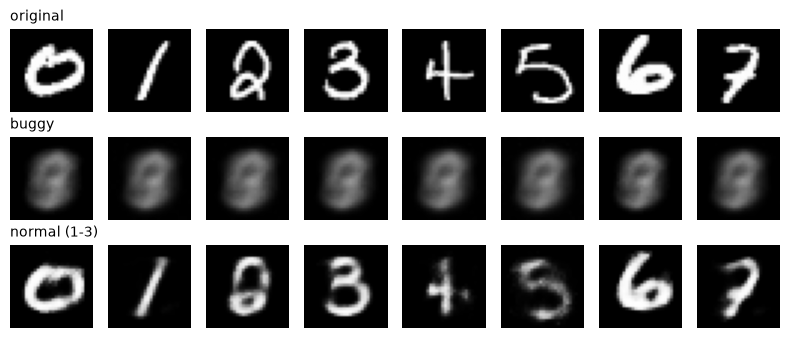

버그판  8장 사이 차이 0.008 | 복원 MSE 0.0681
정상판  8장 사이 차이 0.153 | 복원 MSE 0.0191


In [5]:
# 버그판 학습 (P2_BUG와 같은 버그 · 조건은 1-3과 같게) · 에러 없이 끝남
def train_buggy(model, epochs=10, seed=0):                         # 1-3 train과 한 줄씩 비교할 대상
    torch.manual_seed(seed)                                        # 섞는 순서 고정
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)            # 1-3과 같음
    for epoch in range(epochs):                                    # 1-3과 같음
        model.train()                                              # 1-3과 같음
        perm = torch.randperm(len(Xtr), device=device)             # 입력용 번호 섞기
        other = torch.randperm(len(Xtr), device=device)            # 따로 섞은 번호
        for i in range(0, len(Xtr), 128):                          # 1-3과 같음
            x = Xtr[perm[i:i + 128]]                               # 입력 묶음
            y = Xtr[other[i:i + 128]]                              # x와 짝이 아닌 이미지
            opt.zero_grad()                                        # 1-3과 같음
            loss = F.mse_loss(model(x), y)                         # ← 버그: 정답이 y
            loss.backward()                                        # 1-3과 같음
            opt.step()                                             # 1-3과 같음
        if epoch in (0, epochs // 2 - 1, epochs - 1):              # 1 · 중간 · 끝만
            print(f"  epoch {epoch + 1}  loss {loss.item():.4f}")  # loss만 보면 이상한지 모름
    return model                                                   # 버그판 모델


# 1단계: 코드를 읽기 전에 실행하고 그림부터 봄
torch.manual_seed(0)                                                     # 1-3과 같은 출발점
bug = train_buggy(AutoEncoder(32).to(device))                            # 코드 읽기 전에 먼저 실행
out_bug, out_ok = run(bug, Xte), run(ae32, Xte)                          # 버그판 · 정상판 복원
show([("original", Xte), ("buggy", out_bug), ("normal (1-3)", out_ok)])  # 그림부터 비교


# 2단계: 8장이 서로 얼마나 다른가 (장끼리 차이 = 칸별 표준편차 평균)
for name, out in [("버그판", out_bug), ("정상판", out_ok)]:  # 두 모델을 같은 잣대로
    spread = out[SHOW].std(dim=0).mean().item()              # 8장끼리 얼마나 다른가
    # 0에 가까우면 모두 같은 그림
    print(f"{name}  8장 사이 차이 {spread:.3f} | 복원 MSE {mse(out):.4f}")

**결과** · 예측 정답은 거의 안 내려감 (0.0688 → 0.0697)

- 에러는 없고 loss만 보면 '덜 배웠나' 정도로 보여 놓치기 쉬움
- 그림은 8칸 모두 같은 흐린 8 모양 덩어리
- `epoch 10 loss 0.0697` — 0.06대에서 맴돎 (정상판 1-3은 0.0147)
- `버그판 8장 사이 차이 0.008 | 복원 MSE 0.0681` — 넣은 숫자와 상관없이 같은 그림 = 모든 숫자의 평균 모양 · 버그 줄은 `y = Xtr[other[...]]`
- `정상판 8장 사이 차이 0.153 | 복원 MSE 0.0191` — 칸마다 다른 숫자 모양 · 고친 줄 `F.mse_loss(model(x), x)` (other · y 두 줄 삭제)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">정상판 <code>mse_loss(model(x), x)</code></td>
<td style="text-align: left;">입력과 정답이 <strong>같은 이미지</strong></td>
<td style="text-align: left;">오토인코더 학습 (기본)</td>
</tr>
<tr>
<td style="text-align: left;">버그판 <code>mse_loss(model(x), y)</code></td>
<td style="text-align: left;">정답이 <strong>짝이 아닌 이미지</strong> → 평균 모양만 배움</td>
<td style="text-align: left;">쓰면 안 됨 · 그림이 칸마다 비슷하면 의심</td>
</tr>
<tr>
<td style="text-align: left;">loss로 진단</td>
<td style="text-align: left;">숫자 하나 · 버그를 놓치기 쉬움</td>
<td style="text-align: left;">학습이 도는지만 볼 때</td>
</tr>
<tr>
<td style="text-align: left;">그림 + 장끼리 차이로 진단</td>
<td style="text-align: left;">입력마다 다른 출력이 나오는지 바로 보임</td>
<td style="text-align: left;">결과가 이상할 때 먼저 (기본 선택)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 모양이 같으면 짝이 틀려도 에러가 나지 않음
> - 그림을 원본과 **한 열씩** 맞대어 확인

> ✅ **한 줄 정리** · 에러 없이 결과가 이상하면 손실의 입력 · 정답 자리가 같은 이미지의 짝인지부터 확인한다.

**딥러닝 코드에서는**

- 데이터를 불러올 때 입력과 정답(라벨)을 **따로 섞는** 실수가 같은 증상
- 오토인코더-2 2-1 '어긋난 짝'으로 이어짐

---
## 2. 설계 선택 비교

> **이 장의 흐름**
>
> - 1장에서 돌아가는 오토인코더를 만들었다
> - 끝 함수 · 손실 · 잠재 크기는 사람이 고르는 설계라, 하나씩 바꿔 같은 잣대로 비교하고 PCA 기준선과도 견줌

**파이프라인 위치** · ④ 평가 · ⑤ 설계 선택 · ⑥ 활용 — 출력 범위, 손실 눈금, 잠재 공간, 기준선

### 2-1. `A` 마지막 Sigmoid 있음 vs 없음 · `nn.Sigmoid` <sub>day01 p36–37</sub>

> 🎯 **디코더 끝에 Sigmoid를 두는 이유는 무엇이고, 빼면 무엇이 달라지는가?**

💡 **쉽게 말하면**

- Sigmoid는 **값을 0~1 상자에 눌러 담는 뚜껑**.
- 원본 픽셀이 0~1이니 출력도 같은 상자에 넣어 두면 그림으로 그대로 쓸 수 있음.

**실행 흐름**

1. Sigmoid만 뗀 모델을 같은 조건으로 학습
2. 출력 범위 · 0~1 밖 비율 · 복원 MSE 비교

**먼저 예측** · Sigmoid 없이 학습하면 출력에 0보다 작은 값이 나올까? — 답은 코드 실행 결과 아래에

In [6]:
# 마지막 Sigmoid를 뺀 디코더 (나머지는 같음)
class AENoSigmoid(AutoEncoder):           # 1-2 모델을 물려받아 한 곳만 바꿈
    def __init__(self, latent_dim=32):    # 부모와 같은 인자
        super().__init__(latent_dim)      # 부모 층을 그대로 만든 뒤
        self.decoder = self.decoder[:-1]  # Sigmoid만 떼어 냄


# 같은 조건으로 학습 (5 epoch · seed 0)
torch.manual_seed(0)                          # 1-3과 같은 출발점
ae_nosig = train(AENoSigmoid(32).to(device))  # 같은 조건 · 10 epoch


# 출력 범위 · 0~1 밖 비율 · 복원 MSE 비교
for name, m in [("Sigmoid 있음", ae32), ("Sigmoid 없음", ae_nosig)]:       # 두 모델 비교
    out = run(m, Xte)                                                      # 평가 1만 장 복원
    outside = ((out < 0) | (out > 1)).float().mean().item()                # 픽셀 범위 밖 비율
    print(f"{name}  범위 {out.min().item():.2f} ~ {out.max().item():.2f}"  # 최솟값 ~ 최댓값
          f" | 0~1 밖 {outside:.1%} | MSE {mse(out):.4f}")

  epoch 1  loss 0.0365


  epoch 5  loss 0.0198


  epoch 10  loss 0.0125
Sigmoid 있음  범위 0.00 ~ 1.00 | 0~1 밖 0.0% | MSE 0.0191
Sigmoid 없음  범위 -0.63 ~ 1.56 | 0~1 밖 41.7% | MSE 0.0170


**결과** · 예측 정답은 나옴 — 출력의 40% 이상이 0~1 밖

- `Sigmoid 있음 범위 0.00 ~ 1.00 | 0~1 밖 0.0% | MSE 0.0191` — 항상 픽셀 범위 안
- `Sigmoid 없음 범위 -0.63 ~ 1.56 | 0~1 밖 41.7%` — 그림 · 저장에 바로 못 쓰는 값이 섞임 (배경이 살짝 음수 등)
- `MSE 0.0170` — 이번 10 epoch에선 오히려 조금 작음 → Sigmoid 양 끝은 기울기가 작아 학습이 느림

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">Sigmoid 있음</td>
<td style="text-align: left;">출력이 <strong>항상 0~1</strong> · 양 끝 근처에서 학습이 느림</td>
<td style="text-align: left;">입력을 0~1로 맞춘 이미지 복원 · BCE 손실 (기본 선택)</td>
</tr>
<tr>
<td style="text-align: left;">Sigmoid 없음 (Linear 그대로)</td>
<td style="text-align: left;">출력 범위 <strong>제한 없음</strong> · 0~1 밖 값이 섞임</td>
<td style="text-align: left;">평균 0 · 표준편차 1로 정규화한 입력 · 범위가 정해지지 않은 값(신호 등)</td>
</tr>
<tr>
<td style="text-align: left;">Sigmoid 없음 + <code>clamp(0, 1)</code></td>
<td style="text-align: left;">그릴 때만 0~1로 자름 (학습엔 영향 없음)</td>
<td style="text-align: left;">Sigmoid 없이 학습한 출력을 그림으로 볼 때</td>
</tr>
<tr>
<td style="text-align: left;">Tanh</td>
<td style="text-align: left;">출력 -1~1</td>
<td style="text-align: left;">입력을 -1~1로 정규화했을 때 (GAN 생성자 등)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 출력 끝 함수는 **입력의 값 범위**에 맞춤
> - 0~1이면 Sigmoid, -1~1이면 Tanh, 범위가 정해지지 않았으면 없음

> ✅ **한 줄 정리** · 입력을 0~1로 맞췄다면 디코더 끝에 Sigmoid를 두어 출력도 같은 범위에 넣는다.

**딥러닝 코드에서는**

- `transforms.Normalize(mean, std)`로 정규화한 이미지를 복원하면 값이 0~1 밖이라 Sigmoid를 쓰면 안 됨
- 정규화와 끝 함수를 짝지어 확인

### 2-2. `B` MSE vs BCE 손실 · `F.binary_cross_entropy` <sub>보강</sub>

> 🎯 **복원 손실로 MSE 대신 BCE를 쓰면 무엇이 달라지는가?**

💡 **쉽게 말하면**

- MSE는 **칸마다 차이의 제곱**, BCE는 **각 칸을 '흰색일 확률'로 보고 얼마나 틀렸나**를 잼.
- 둘 다 원본에 가까울수록 작아지지만 눈금이 다름.

**실행 흐름**

1. 같은 모델 · 같은 seed · 손실만 BCE
2. 평가는 둘 다 MSE로 · 그림
3. 0~1 밖 값을 BCE에 넣어 에러 확인

**먼저 예측** · BCE 모델의 epoch loss(0.1대)가 MSE 모델(0.01대)보다 크면 더 못한 모델일까? — 답은 코드 실행 결과 아래에

  epoch 1  loss 0.2491


  epoch 5  loss 0.1549


  epoch 10  loss 0.1029
MSE로 학습 → 복원 MSE 0.0191
BCE로 학습 → 복원 MSE 0.0187


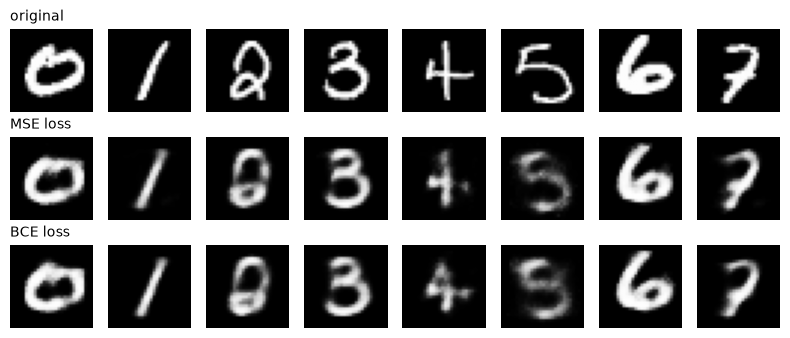

RuntimeError: all elements of input should be between 0 and 1


In [7]:
# 같은 모델 · 같은 seed · 손실만 BCE로 바꿔 학습
torch.manual_seed(0)                                                        # 1-3과 같은 출발점
ae_bce = train(AutoEncoder(32).to(device), loss_fn=F.binary_cross_entropy)  # 손실만 BCE


# 평가는 둘 다 같은 잣대(MSE)로
out_mse, out_bce = run(ae32, Xte), run(ae_bce, Xte)                      # 두 모델 복원
print(f"MSE로 학습 → 복원 MSE {mse(out_mse):.4f}")                       # 같은 잣대(평가 MSE)로
print(f"BCE로 학습 → 복원 MSE {mse(out_bce):.4f}")                       # 같은 잣대(평가 MSE)로
show([("original", Xte), ("MSE loss", out_mse), ("BCE loss", out_bce)])  # 그림도 비교


# BCE는 출력이 0~1이어야 함 → Sigmoid 없는 출력이면 에러
try:
    F.binary_cross_entropy(torch.tensor([1.3]), torch.tensor([1.0]))  # 1을 넘는 출력을 일부러
except RuntimeError as e:                                             # 에러를 잡아 멈추지 않게
    print("RuntimeError:", e)                                         # 에러 문장 그대로 읽기

**결과** · 예측 정답은 아님

- 손실 종류마다 눈금이 달라 loss끼리는 비교 불가
- 같은 잣대(평가 MSE)로 재면 거의 같고, 그림도 거의 같음 (BCE 쪽 4가 조금 더 또렷)
- `epoch 10 loss 0.1029` — BCE의 눈금 · 1-3의 MSE loss와 직접 비교 불가
- `MSE로 학습 → 복원 MSE 0.0191` — 같은 평가 1만 장
- `BCE로 학습 → 복원 MSE 0.0187` — 같은 잣대로 재면 비슷함 (이번 실행)
- `RuntimeError: all elements of input should be between 0 and 1` — BCE는 출력이 0~1이어야 함 → 끝에 Sigmoid 필수

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">MSE <code>F.mse_loss</code></td>
<td style="text-align: left;">칸마다 (차이)² 평균 · 큰 차이에 벌점이 큼</td>
<td style="text-align: left;">값 범위가 자유로운 출력 · 기본 선택</td>
</tr>
<tr>
<td style="text-align: left;">BCE <code>F.binary_cross_entropy</code></td>
<td style="text-align: left;">칸을 0~1 확률로 보고 로그 손실 · <strong>출력 0~1 필수</strong></td>
<td style="text-align: left;">흑백에 가까운 이미지(MNIST · 문서) + 끝이 Sigmoid일 때</td>
</tr>
<tr>
<td style="text-align: left;"><code>F.binary_cross_entropy_with_logits</code></td>
<td style="text-align: left;">Sigmoid를 <strong>손실 안에서</strong> 계산 → 수치가 안정적</td>
<td style="text-align: left;">디코더 끝에 Sigmoid 없이 BCE를 쓰고 싶을 때</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 손실 종류가 다르면 loss 숫자끼리 비교 금지
> - 평가는 **같은 잣대 하나**(평가 MSE 등)로

> ✅ **한 줄 정리** · MSE와 BCE는 눈금이 다른 손실이라, 고를 때는 출력 범위를 보고 비교할 때는 같은 평가 지표로 잰다.

**딥러닝 코드에서는**

- 문서 이미지(흰 배경 · 검은 글자)는 거의 흑백이라 BCE도 후보
- 결과 비교는 RMSE
- PSNR 같은 같은 잣대로 (오토인코더-2 3장)

### 2-3. `A` 잠재 공간 · `model.encoder(x)` <sub>코드잇 p6–14 · day01 p58 · p62–63</sub>

> 🎯 **가운데 32개 숫자에는 무엇이 담기며, 라벨 없이도 숫자끼리 구별될까?**

💡 **쉽게 말하면**

- 잠재 벡터는 **그림 한 장의 주소**.
- 비슷한 그림은 가까운 주소를 받는데, 주소 체계(각 칸의 뜻)는 모델이 스스로 정함.

**실행 흐름**

1. 평가 1만 장
2. 인코더만 통과
3. (10000, 32)
4. 같은 숫자끼리 · 다른 숫자끼리 평균 거리 (픽셀 vs 잠재)
5. 숫자 0 · 1 색 띠

**먼저 예측** · 라벨을 한 번도 안 썼는데, 잠재 공간에서 같은 숫자끼리 더 가까울까? — 답은 코드 실행 결과 아래에

잠재 벡터 모양 (10000, 32)
숫자 0 한 장 앞 5개: [-3.15  7.48 -5.85  7.05 -2.21]
픽셀 784  같은 숫자 8.56 | 다른 숫자 9.98 | 비율 1.17배
잠재 32  같은 숫자 16.55 | 다른 숫자 21.20 | 비율 1.28배


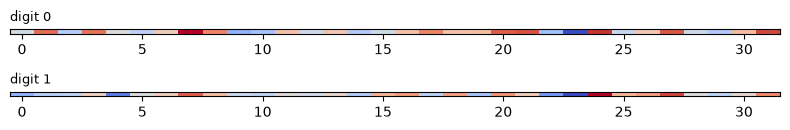

In [8]:
# 평가 1만 장을 인코더에만 통과 → 잠재 벡터
with torch.no_grad():                                           # 기울기 계산 끔 (꺼내기만)
    Z = torch.cat([ae32.encoder(Xte[i:i + 2000])                # 인코더만 통과 · 2,000장씩
                   for i in range(0, 10000, 2000)]).cpu()
print("잠재 벡터 모양", tuple(Z.shape))                         # (장 수, 32)
print("숫자 0 한 장 앞 5개:", Z[SHOW[0], :5].numpy().round(2))  # 평범한 숫자들


# 같은 숫자끼리 · 다른 숫자끼리 평균 거리 (라벨은 계산 뒤에만 씀)
def mean_dist(A, idx):                                    # 같은 숫자 · 다른 숫자 평균 거리
    D = torch.cdist(A[idx], A[idx])                       # 모든 짝의 거리
    same = (yte[idx][:, None] == yte[idx][None, :])       # 짝마다 라벨이 같은가
    return D[same].mean().item(), D[~same].mean().item()  # (같은, 다른) 평균


idx = torch.arange(2000)                                    # 앞 2,000장
P = Xte.flatten(1).cpu()                                    # 픽셀 784개
for name, A in [("픽셀 784", P), ("잠재 32", Z)]:           # 두 공간을 같은 방법으로
    s, d = mean_dist(A, idx)                                # 라벨은 계산 뒤 묶기에만
    print(f"{name}  같은 숫자 {s:.2f} | 다른 숫자 {d:.2f}"  # 비율이 클수록 잘 갈림
          f" | 비율 {d / s:.2f}배")


# 숫자 0 · 1의 잠재 벡터 32칸을 색 띠로
fig, axes = plt.subplots(2, 1, figsize=(8, 1.4))                    # 띠 두 줄
for ax, k in zip(axes, [SHOW[0], SHOW[1]]):                         # 숫자 0 · 1 한 장씩
    ax.imshow(Z[k][None], cmap="coolwarm", aspect="auto")           # 32칸을 색으로 (음수 파랑)
    ax.set_yticks([])                                               # 세로 눈금 숨김
    ax.set_title(f"digit {yte[k].item()}", loc="left", fontsize=9)  # 어느 숫자인지
plt.tight_layout()                                                  # 간격 정리
plt.show()                                                          # 그림 출력

**결과** · 예측 정답은 가까움 — 다른 숫자끼리 거리가 같은 숫자끼리의 1.28배 (픽셀 784개에서는 1.17배)

- `잠재 벡터 모양 (10000, 32)` — 한 장 = 숫자 32개 = 잠재 공간의 점 하나
- `숫자 0 한 장 앞 5개: [-3.15 7.48 -5.85 7.05 -2.21]` — 음수 · 양수가 섞인 평범한 숫자 · 칸마다 정해 준 뜻 없음
- `픽셀 784 같은 숫자 8.56 | 다른 숫자 9.98 | 비율 1.17배` — 픽셀 그대로도 같은 숫자가 조금 더 가까움
- `잠재 32 같은 숫자 16.55 | 다른 숫자 21.20 | 비율 1.28배` — 값을 4%로 줄였는데 숫자 구별은 더 뚜렷

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">픽셀 784개</td>
<td style="text-align: left;">보이는 그대로 · 이웃 픽셀 정보가 겹침</td>
<td style="text-align: left;">그림을 그대로 보여 줄 때</td>
</tr>
<tr>
<td style="text-align: left;">잠재 벡터 32개</td>
<td style="text-align: left;">학습이 고른 <strong>요약</strong> · 칸의 뜻은 사람이 모름</td>
<td style="text-align: left;">비슷한 그림 찾기 · 군집 · 시각화 · 이상 탐지의 입력</td>
</tr>
<tr>
<td style="text-align: left;">라벨 (0~9)</td>
<td style="text-align: left;">사람이 붙인 정답 · 학습에 안 씀</td>
<td style="text-align: left;">학습이 끝난 뒤 <strong>색칠 · 확인용</strong>으로만</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 잠재 벡터의 칸마다 '굵기'
> - '기울기' 같은 이름이 있다고 볼 근거 없음
> - 복원 오차를 줄이려 모델이 정한 숫자일 뿐

> ✅ **한 줄 정리** · 인코더만 통과시킨 잠재 벡터가 그림의 요약이며, 라벨 없이 배워도 비슷한 그림끼리 가까이 놓인다.

**딥러닝 코드에서는**

- 표현 학습(representation learning)
- 학습한 인코더의 출력을 분류기 · 검색 · 군집
- 이상 탐지의 입력 특징으로 재사용

### 2-4. `A` 잠재 크기 작게 vs 크게 · `latent_dim` <sub>day01 p72–97</sub>

> 🎯 **통로(잠재 크기)를 넓히면 무엇이 늘고, 얼마나 좁혀도 되는가?**

💡 **쉽게 말하면**

- 메모 칸이 **2칸이면 '굵고 기울어진 숫자' 정도만**, 128칸이면 거의 다 적을 수 있음.
- 대신 칸이 넓을수록 베끼기에 가까워져 '무엇이 중요한가'를 덜 고름.

<img src="images/ae1_latent.png" alt="잠재 크기별 남는 값과 파라미터" width="752">

**실행 흐름**

1. 잠재 2 · 8 · 32 · 128 모델
2. 남는 값 비율 · 파라미터 수
3. 바뀌는 두 층 계산

**먼저 예측** · 잠재를 2 → 128로 64배 넓히면 파라미터는 몇 배가 될까? — 답은 코드 실행 결과 아래에

In [9]:
# 잠재 크기별 파라미터 수 (학습 없이 세기만)
for d in [2, 8, 32, 128]:                                            # 잠재 크기 네 가지
    n = sum(p.numel() for p in AutoEncoder(d).parameters())          # 가중치 개수 합
    print(f"잠재 {d:>3} | 남는 값 {d / 784:6.1%} | 파라미터 {n:,}")  # 압축률 · 파라미터


# 바뀌는 곳은 통로 앞뒤 두 층뿐: 128×d + d  +  d×128 + 128
d = 32                                                  # 1-3 모델 크기
print("통로 앞뒤 두 층:", 128 * d + d + d * 128 + 128)  # 바뀌는 두 층만 손계산

잠재   2 | 남는 값   0.3% | 파라미터 202,258
잠재   8 | 남는 값   1.0% | 파라미터 203,800
잠재  32 | 남는 값   4.1% | 파라미터 209,968
잠재 128 | 남는 값  16.3% | 파라미터 234,640
통로 앞뒤 두 층: 8352


**결과** · 예측 정답은 약 1.16배 (202,258 → 234,640) — 바뀌는 곳은 통로 앞뒤 두 층뿐

- `잠재 2 | 남는 값 0.3% | 파라미터 202,258` — 입력의 0.3%만 남기는 극단적 압축
- `잠재 32 | 남는 값 4.1% | 파라미터 209,968` — 1-3 모델 · 수업 슬라이드 값과 같음
- `잠재 128 | 남는 값 16.3% | 파라미터 234,640` — 64배 넓혀도 파라미터는 16% 증가
- `통로 앞뒤 두 층: 8352` — 잠재 32일 때 128 × 32 + 32 + 32 × 128 + 128 = 8352

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">작게 (2 · 8)</td>
<td style="text-align: left;">압축이 강함 → <strong>흐림 · 다른 숫자 모양</strong>이 나올 수 있음 · 2이면 평면에 그려짐</td>
<td style="text-align: left;">시각화 · 강한 요약이 필요할 때</td>
</tr>
<tr>
<td style="text-align: left;">중간 (16 · 32)</td>
<td style="text-align: left;">복원과 요약의 균형</td>
<td style="text-align: left;">처음 시작할 때의 기본값</td>
</tr>
<tr>
<td style="text-align: left;">크게 (128 이상)</td>
<td style="text-align: left;">복원 오차는 작지만 <strong>베끼기에 가까워짐</strong> · 무엇을 남길지 덜 고름</td>
<td style="text-align: left;">복원 품질이 최우선일 때 · 노이즈 제거처럼 다른 요구를 함께 둘 때</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 잠재 크기는 정답이 없는 **설계 선택**
> - 크기 하나만 바꿔 같은 조건으로 학습
> - 같은 평가 이미지로 비교 (4장 종합 실습)

> ✅ **한 줄 정리** · 잠재 크기는 통로 앞뒤 두 층만 바꾸는 숫자 하나지만 복원 품질과 압축 정도를 함께 바꾸므로, 쓰임에 맞춰 골라야 한다.

**딥러닝 코드에서는**

- `latent_dim`은 하이퍼파라미터 · 학습률
- 배치 크기처럼 하나씩 바꿔 검증 데이터로 고름 (오토인코더-2 4장 '하나만 바꾸기')

### 2-5. `B` 오토인코더 vs PCA · `PCA(n_components=32)` <sub>코드잇 p3–5 · 보강</sub>

> 🎯 **같은 32개로 줄일 때, 오토인코더와 PCA는 무엇이 다르고 어느 쪽이 더 잘 복원하는가?**

💡 **쉽게 말하면**

- PCA는 **자를 대고 곧은 축으로만 요약**, 오토인코더는 **휘어진 곡선으로도 요약**할 수 있음.
- 대신 PCA는 계산 한 번으로 끝나고 오토인코더는 학습이 필요.

**실행 흐름**

1. 학습 1만 장으로 PCA 32축 찾기
2. 압축(transform)
3. 복원(inverse_transform)
4. 같은 평가 MSE로 AE 32와 비교 · 그림

**먼저 예측** · 이번 조건(학습 1만 장 · 10 epoch)에서 복원 MSE가 더 작은 쪽은? — 답은 코드 실행 결과 아래에

PCA 잠재 모양 (10000, 32)
PCA 32  복원 MSE 0.0170
AE  32  복원 MSE 0.0191
PCA 출력 범위 -0.67 ~ 1.53


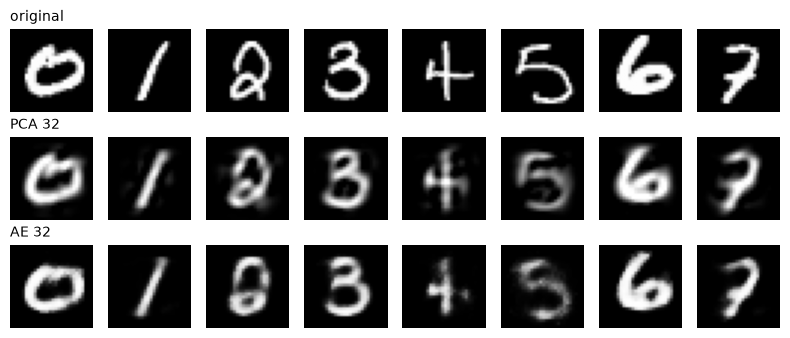

In [10]:
# PCA: 학습 1만 장으로 주성분 32개 찾기 (선형 · 한 번에 계산)
Xtr_np = Xtr.flatten(1).cpu().numpy()                   # (10000, 784)
Xte_np = Xte.flatten(1).cpu().numpy()                   # sklearn은 넘파이 (장, 784)
pca = PCA(n_components=32, random_state=0).fit(Xtr_np)  # 학습 1만 장으로 축 32개


# 압축(transform) → 복원(inverse_transform) → 원래 모양
Zp = pca.transform(Xte_np)                                       # (10000, 32)
rec = pca.inverse_transform(Zp).reshape(-1, 1, 28, 28)           # 32개 → 784개 → 그림 모양
out_pca = torch.tensor(rec, dtype=torch.float32, device=device)  # mse()에 넣으려고 텐서로
print("PCA 잠재 모양", Zp.shape)                                 # AE 잠재와 같은 크기
print(f"PCA 32  복원 MSE {mse(out_pca):.4f}")                    # 같은 평가 1만 장
print(f"AE  32  복원 MSE {mse(run(ae32, Xte)):.4f}")             # 같은 평가 1만 장
print(f"PCA 출력 범위 {rec.min():.2f} ~ {rec.max():.2f}")        # 선형이라 0~1 밖도 나옴
show([("original", Xte), ("PCA 32", out_pca.clamp(0, 1)),        # 그릴 때만 0~1로 자름
      ("AE 32", run(ae32, Xte))])

**결과** · 예측 정답은 PCA (0.0170 < 0.0191)

- 오토인코더가 늘 이기는 것은 아님
- 그런데 그림은 PCA 쪽이 더 흐리고 획 주변에 옅은 잔상이 보임 (MSE가 작다고 눈으로도 낫다는 보장은 없음)
- `PCA 잠재 모양 (10000, 32)` — 오토인코더 잠재 벡터와 같은 크기
- `PCA 32 복원 MSE 0.0170` — 계산 한 번 · 학습 없음
- `AE 32 복원 MSE 0.0191` — 짧은 학습 · Dense 구조에서는 PCA가 조금 나음
- `PCA 출력 범위 -0.67 ~ 1.53` — 선형 복원이라 0~1 밖 값이 나옴 → 그림은 clamp

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">PCA</td>
<td style="text-align: left;"><strong>선형</strong> · 분산이 큰 축을 계산으로 바로 찾음 · 학습 불필요 · 늘 같은 결과</td>
<td style="text-align: left;">빠른 차원 축소 · 기준선 · 시각화 전처리</td>
</tr>
<tr>
<td style="text-align: left;">오토인코더 (Dense)</td>
<td style="text-align: left;"><strong>비선형</strong>(ReLU) · 학습 필요 · 구조 · 손실 · 끝 함수를 바꿀 수 있음</td>
<td style="text-align: left;">데이터가 많고 구조가 복잡할 때 · 입력 ≠ 정답인 과제(노이즈 제거)</td>
</tr>
<tr>
<td style="text-align: left;">Conv 오토인코더</td>
<td style="text-align: left;">이미지의 <strong>이웃 관계</strong>를 씀 (3-5)</td>
<td style="text-align: left;">이미지 복원 · 이 노트북에서 MSE가 가장 작음</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 새 모델은 PCA 같은 **간단한 기준선**과 먼저 비교
> - 숫자(MSE)와 그림이 다른 쪽을 가리킬 수 있어 둘 다 봄 (오토인코더-2 3장)

> ✅ **한 줄 정리** · PCA는 계산 한 번으로 구하는 선형 압축이고 오토인코더는 학습하는 비선형 압축이므로, 오토인코더를 쓸 때는 PCA를 기준선으로 함께 잰다.

**딥러닝 코드에서는**

- 은닉층에 활성화 함수가 없는 선형 오토인코더를 MSE로 학습하면 PCA와 같은 공간을 배움 → 오토인코더 = 'PCA의 비선형 확장'

---
## 3. Conv 오토인코더와 크기 맞추기

> **이 장의 흐름**
>
> - 2장까지는 그림을 784칸 한 줄로 폈다
> - 위아래 이웃 픽셀이 28칸 떨어짐.
> - 그림 모양 그대로 Conv로 줄이고 늘리면 층마다 크기를 직접 맞춰야 함

**파이프라인 위치** · ② 모델 설계 · ④ 평가 — 크기 공식, 늘리는 층, 어긋난 층 찾기, Conv AE

### 3-1. `A` Conv2d로 줄이기 · `Conv2d(k3, s2, p1)` <sub>day01 p134–146 · CNN-1 참조</sub>

> 🎯 **그림을 펴지 않고 줄이면 크기는 어떻게 정해지고, 홀수 크기면 어떻게 되는가?**

💡 **쉽게 말하면**

- stride 2는 **두 칸마다 하나씩 고르기**.
- 짝수 칸이면 딱 반, 홀수 칸이면 남는 끝 칸도 뽑혀 반보다 하나 많음.

**실행 흐름**

1. 공식 함수
2. 28 · 14 · 7 · 30 · 15를 실제 Conv2d에 통과
3. 공식과 대조
4. 채널 = 필터 수

**크기 계산표** · CNN 정리본과 같은 공식 · 이 노트북에서는 여기 한 번만 적고 뒤에서는 이 표를 참조

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">층</th>
<th style="text-align: left;">공식 (n = 들어가는 크기)</th>
<th style="text-align: left;">예 (k3 · s2 · p1)</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>Conv2d</code></td>
<td style="text-align: left;">(n + 2p − k) // s + 1</td>
<td style="text-align: left;">28 → 14 · 15 → 8</td>
</tr>
<tr>
<td style="text-align: left;"><code>ConvTranspose2d</code></td>
<td style="text-align: left;">(n − 1) × s − 2p + k + op</td>
<td style="text-align: left;">7 → 13 · op 1이면 14</td>
</tr>
</tbody>
</table>

**먼저 예측** · Conv2d(k3, s2, p1)에 15×15를 넣으면? — 답은 코드 실행 결과 아래에

In [11]:
# 손계산 공식: (n + 2p - k) // s + 1  (CNN 크기 공식 · 이 노트북에서 1회)
def conv_out(n, k=3, s=2, p=1):      # 들어가는 크기 → 나오는 크기
    return (n + 2 * p - k) // s + 1  # // = 내림


# 공식 ↔ 실제 Conv2d 결과 대조
down = nn.Conv2d(1, 1, kernel_size=3, stride=2, padding=1)        # 확인용 층 하나
for n in [28, 14, 7, 30, 15]:                                     # 짝수 · 홀수 섞어서
    real = down(torch.zeros(1, 1, n, n)).shape[-1]                # 실제 통과시킨 크기
    kind = "짝수" if n % 2 == 0 else "홀수"                       # 짝 · 홀 표시
    print(f"{n:>2} ({kind}) → 공식 {conv_out(n)} | 실제 {real}")  # 공식 = 실제인지


# 채널: 필터 수 = 결과 판 수 (세로 · 가로와 따로 정함)
conv = nn.Conv2d(16, 32, 3, stride=2, padding=1)                           # 받는 판 16 · 필터 32
print("가중치 모양", tuple(conv.weight.shape))                             # (필터, 받는 판, 3, 3)
print("1×28×28 →", tuple(nn.Conv2d(1, 16, 3, 2, 1)(Xte[:1].cpu()).shape))  # 채널 1 → 16

28 (짝수) → 공식 14 | 실제 14
14 (짝수) → 공식 7 | 실제 7
 7 (홀수) → 공식 4 | 실제 4
30 (짝수) → 공식 15 | 실제 15
15 (홀수) → 공식 8 | 실제 8
가중치 모양 (32, 16, 3, 3)
1×28×28 → (1, 16, 14, 14)


**결과** · 예측 정답은 `8×8` — 홀수라 반(7.5)을 올린 8

- `28 (짝수) → 공식 14 | 실제 14` — 짝수 → 딱 반
- `7 (홀수) → 공식 4 | 실제 4` — 홀수 → 반(3.5)을 올림
- `15 (홀수) → 공식 8 | 실제 8` — 30 → 15 → 8: 두 번째 층에 홀수가 들어감 (3-4로 이어짐)
- `가중치 모양 (32, 16, 3, 3)` — 필터 32개 × 받는 판 16장 × 3×3
- `1×28×28 → (1, 16, 14, 14)` — 채널 1 → 16(필터 수) · 세로 · 가로는 반

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>Conv2d(k3, s2, p1)</code></td>
<td style="text-align: left;">세로 · 가로 <strong>반</strong> (홀수면 올림)</td>
<td style="text-align: left;">인코더에서 크기를 줄일 때 (기본 선택)</td>
</tr>
<tr>
<td style="text-align: left;"><code>Conv2d(k3, s1, p1)</code></td>
<td style="text-align: left;">크기 <strong>그대로</strong> · 특징만 바꿈</td>
<td style="text-align: left;">같은 크기에서 층을 더 쌓을 때</td>
</tr>
<tr>
<td style="text-align: left;"><code>MaxPool2d(2)</code></td>
<td style="text-align: left;">가중치 없이 2×2 중 최댓값 · 홀수면 <strong>내림</strong></td>
<td style="text-align: left;">분류 CNN에서 줄일 때 (CNN 정리본)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 홀수 크기가 들어가면 줄일 때 올림
> - 나중에 두 배로 늘리면 원래보다 1칸 큼 (30 → 15 → 8 → 16 → 32)

> ✅ **한 줄 정리** · Conv2d k3 s2 p1은 짝수 크기를 딱 반으로, 홀수 크기는 반보다 한 칸 많게 줄이며 채널 수는 필터 수로 따로 정한다.

**딥러닝 코드에서는**

- `nn.Conv2d(1, 16, 3, stride=2, padding=1)  # 1×28×28 → 16×14×14`처럼 **줄 끝에 크기 주석** (미션 안내의 요구사항)

### 3-2. `A` 늘리기 세 방법 · `ConvTranspose2d` · `Upsample` <sub>day01 p147–160</sub>

> 🎯 **디코더에서 크기를 딱 두 배로 늘리려면 어떤 층 · 설정을 쓰는가?**

💡 **쉽게 말하면**

- 전치 합성곱은 **칸 사이를 벌리고 틈을 채워 그리기**.
- 칸 32개 사이의 틈은 31개뿐이라 그냥 벌리면 63 — 맨 끝에 한 칸을 더 줘야 64.

<img src="images/ae1_convt.png" alt="칸 사이를 벌리면 한 칸 모자람" width="763">

**실행 흐름**

1. 32×32 · 16채널
2. ConvT k3 · ConvT k3 + op1 · ConvT k4 · Upsample + Conv
3. 크기 · 파라미터
4. 공식 대조
5. op 없이 두 번

**먼저 예측** · ConvTranspose2d(k3, s2, p1)로 32×32를 늘리면? — 답은 코드 실행 결과 아래에

In [12]:
# 늘리는 공식: (n - 1) × s - 2p + k + op
def up_out(n, k=3, s=2, p=1, op=0):      # 늘리는 층의 크기 공식
    return (n - 1) * s - 2 * p + k + op  # 칸 + 틈 · op는 끝 한 칸


# 32×32 · 16채널을 세 방법으로 늘리기
t = torch.zeros(1, 16, 32, 32)                                  # 16채널 · 32×32
ways = {                                                        # 늘리는 방법 네 가지
    "ConvT k3 s2 p1": nn.ConvTranspose2d(16, 8, 3, 2, 1),
    "ConvT k3 s2 p1 op1": nn.ConvTranspose2d(16, 8, 3, 2, 1,
                                             output_padding=1),
    "ConvT k4 s2 p1": nn.ConvTranspose2d(16, 8, 4, 2, 1),
    "Upsample + Conv k3": nn.Sequential(
        nn.Upsample(scale_factor=2), nn.Conv2d(16, 8, 3, padding=1)),
}
for name, layer in ways.items():                                # 방법마다
    n = sum(p.numel() for p in layer.parameters())              # 가중치 개수
    print(f"{name:<20} → {layer(t).shape[-1]} | 파라미터 {n}")  # 나온 크기 · 가중치


# 공식과 대조
print("공식", up_out(32), up_out(32, op=1), up_out(32, k=4))  # 손계산과 대조


# 두 번 늘리면 모자람이 쌓임: 7 → 13 → 25 (op 없이)
print("op 없이 두 번:", 7, "→", up_out(7), "→", up_out(up_out(7)))  # 모자람이 쌓이는지

ConvT k3 s2 p1       → 63 | 파라미터 1160
ConvT k3 s2 p1 op1   → 64 | 파라미터 1160
ConvT k4 s2 p1       → 64 | 파라미터 2056
Upsample + Conv k3   → 64 | 파라미터 1160
공식 63 64 64
op 없이 두 번: 7 → 13 → 25


**결과** · 예측 정답은 `63×63` — 칸 32 + 틈 31, 두 배보다 1칸 모자람

- `ConvT k3 s2 p1 → 63 | 파라미터 1160` — 32 + 31 = 63 · 두 배에서 1칸 모자람
- `ConvT k3 s2 p1 op1 → 64 | 파라미터 1160` — output_padding=1로 끝 한 칸 추가 · 가중치 수는 같음
- `ConvT k4 s2 p1 → 64 | 파라미터 2056` — 커널을 한 칸 넓혀 채움 · 16 × 8 × 4 × 4 + 8 = 2056
- `Upsample + Conv k3 → 64 | 파라미터 1160` — 먼저 두 배로 키우고(가중치 없음) 크기 유지 Conv
- `op 없이 두 번: 7 → 13 → 25` — 모자람이 쌓임 (28이 아닌 25)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>Conv2d</code></td>
<td style="text-align: left;"><strong>줄이기</strong> (stride 2) · 유지 (stride 1)</td>
<td style="text-align: left;">인코더</td>
</tr>
<tr>
<td style="text-align: left;"><code>ConvTranspose2d(k3, s2, p1, op1)</code></td>
<td style="text-align: left;">칸 사이를 벌려 <strong>두 배</strong> · 학습하는 가중치로 늘림</td>
<td style="text-align: left;">디코더 기본 선택 (수업 · 미션 Conv AE)</td>
</tr>
<tr>
<td style="text-align: left;"><code>ConvTranspose2d(k4, s2, p1)</code></td>
<td style="text-align: left;">output_padding 없이 두 배 · 가중치가 조금 더 많음</td>
<td style="text-align: left;">GAN 생성자 · U-Net 등 여러 구현의 기본 설정</td>
</tr>
<tr>
<td style="text-align: left;"><code>Upsample(×2)</code> + <code>Conv2d(k3, p1)</code></td>
<td style="text-align: left;">먼저 <strong>보간으로 키우고</strong>(가중치 없음) Conv로 다듬음</td>
<td style="text-align: left;">전치 합성곱의 바둑판 무늬(checkerboard)가 거슬릴 때</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - ConvTranspose2d k3 s2 p1에 output_padding을 빠뜨리면 에러 없이 1칸씩 모자람
> - 두 번이면 25 (3-5 실수 ②)

> ✅ **한 줄 정리** · 딱 두 배로 늘리려면 output_padding=1 · kernel 4 · Upsample + Conv 중 하나를 쓰고, 크기는 공식으로 먼저 센다.

**딥러닝 코드에서는**

- 세그멘테이션(U-Net)
- 생성 모델(GAN 생성자)의 디코더도 이 '늘리는 층'으로 해상도를 되돌림

### 3-3. `A` 어긋난 층 찾기 · `for layer in model` <sub>day01 p170–172 · P3</sub>

> 🎯 **마지막 크기가 틀렸을 때, 어느 층에서 처음 어긋났는지 어떻게 찾는가?**

💡 **쉽게 말하면**

- **계산 문제를 한 줄씩 검산**하는 것.
- 마지막 답만 보면 어디서 틀렸는지 모르지만, 줄마다 내 계산과 비교하면 처음 틀린 줄이 바로 보임.

**실행 흐름**

1. 손계산 표 [14, 7, 14, 28]
2. 버그판 층마다 크기
3. 처음 다른 층
4. 그 층 설정 한 곳만 고침
5. 다시 대조

**손계산표** · P3 표 빈칸 정답 (공식은 3-1 표)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">층</th>
<th style="text-align: left;">설정</th>
<th style="text-align: left;">들어가는 크기</th>
<th style="text-align: left;">나오는 크기</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1번째 <code>Conv2d</code></td>
<td style="text-align: left;">k3 · s2 · p1</td>
<td style="text-align: left;">28</td>
<td style="text-align: left;">14</td>
</tr>
<tr>
<td style="text-align: left;">2번째 <code>Conv2d</code></td>
<td style="text-align: left;">k3 · s2 · p1</td>
<td style="text-align: left;">14</td>
<td style="text-align: left;">7</td>
</tr>
<tr>
<td style="text-align: left;">3번째 <code>ConvTranspose2d</code></td>
<td style="text-align: left;">k3 · s2 · p1 · op1</td>
<td style="text-align: left;">7</td>
<td style="text-align: left;">14</td>
</tr>
<tr>
<td style="text-align: left;">4번째 <code>ConvTranspose2d</code></td>
<td style="text-align: left;">k3 · s2 · p1 · op1</td>
<td style="text-align: left;">14</td>
<td style="text-align: left;">28</td>
</tr>
</tbody>
</table>

**먼저 예측** · 버그판의 마지막 크기는 28일까? — 답은 코드 실행 결과 아래에

In [13]:
# 층마다 나오는 크기를 모으는 도구 (P3 검사 도구를 줄인 것)
def trace(model, n=28):                                         # 층마다 나온 크기 목록
    h, sizes = torch.zeros(1, 1, n, n), []                      # 빈 이미지 한 장
    for layer in model:                                         # 층을 하나씩
        h = layer(h)                                            # 통과
        if isinstance(layer, (nn.Conv2d, nn.ConvTranspose2d)):  # 크기를 바꾸는 층만
            sizes.append(h.shape[-1])                           # 끝 숫자 = 가로 크기
    return sizes                                                # 예: [14, 7, 14, 28]


# 손계산 표 (P3 빈칸 정답) · 버그판 모델 (P3 원본)
table_ = [14, 7, 14, 28]                                  # 손계산 표 (P3 정답)
bad = nn.Sequential(                                      # P3 원본 모델
    nn.Conv2d(1, 8, 3, stride=2, padding=1), nn.ReLU(),
    nn.Conv2d(8, 16, 3, stride=2, padding=0), nn.ReLU(),  # ← 다른 곳
    nn.ConvTranspose2d(16, 8, 3, 2, 1, output_padding=1), nn.ReLU(),
    nn.ConvTranspose2d(8, 1, 3, 2, 1, output_padding=1), nn.Sigmoid())


# 표와 찍힌 크기를 층마다 대조 → 처음 다른 층 찾기
got = trace(bad)                                                            # 찍힌 크기
print("표   ", table_)                                                      # 손계산
print("버그판", got)                                                        # 실제
first = next(i for i, (a, b) in enumerate(zip(table_, got)) if a != b)      # 처음 다른 자리
print("처음 다른 층:", first + 1, "번째 →", type(bad[2 * first]).__name__)  # ReLU 건너 층 번호


# 그 층 설정 한 곳만 고침 (padding=0 → 1)
bad[2] = nn.Conv2d(8, 16, 3, stride=2, padding=1)                      # 그 층의 padding만 0 → 1
print("수정판", trace(bad), "→ 통과" if trace(bad) == table_ else "")  # 다시 대조

표    [14, 7, 14, 28]
버그판 [14, 6, 12, 24]
처음 다른 층: 2 번째 → Conv2d
수정판 [14, 7, 14, 28] → 통과


**결과** · 예측 정답은 `24` — 14 → 6 → 12 → 24, 2번째 층에서 처음 어긋남

- `버그판 [14, 6, 12, 24]` — 마지막만 보면 24 (4칸 모자람)
- `처음 다른 층: 2 번째 → Conv2d` — padding=0 → 양옆이 다 있는 칸만 골라 14칸 → 6
- `수정판 [14, 7, 14, 28] → 통과` — padding=1 한 곳만 고침

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">마지막 출력 모양만 확인</td>
<td style="text-align: left;">틀렸다는 것만 앎</td>
<td style="text-align: left;">맞는지 빠르게 볼 때</td>
</tr>
<tr>
<td style="text-align: left;">층마다 모양 찍기 <code>for layer in model</code></td>
<td style="text-align: left;"><strong>처음 어긋난 층</strong>을 찾음</td>
<td style="text-align: left;">크기가 틀렸을 때 (기본 선택)</td>
</tr>
<tr>
<td style="text-align: left;">손계산 표와 대조</td>
<td style="text-align: left;">설정이 의도대로인지까지 확인</td>
<td style="text-align: left;">모델을 처음 설계할 때 (치기 전에 표 먼저)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 다른 층
> - 다른 인자를 바꿔 28을 맞춰도 설계와 다른 모델
> - **처음 다른 층의 설정 한 곳만** 고침

> ✅ **한 줄 정리** · 크기가 틀리면 손계산 표와 층마다 찍힌 크기를 대조해, 처음 달라진 층의 설정 하나만 고친다.

**딥러닝 코드에서는**

- 오토인코더-2 2-3(문서 한 장 통째로 넣기)에서 같은 방법으로 홀수 크기가 처음 들어간 층을 찾음

### 3-4. `A` 입력 크기가 바뀌면 · `out[..., :h, :w]` <sub>day01 p161–168</sub>

> 🎯 **28×28에서 잘 되던 모델에 30×30 · 250×536을 넣으면 왜 크기가 어긋나는가?**

💡 **쉽게 말하면**

- 반으로 두 번 접으려면 **4로 나누어떨어져야** 남는 칸이 없음.
- 30은 4로 안 나뉘어, 접을 때 올린 칸이 펼칠 때 남음.

<img src="images/ae1_sizeflow.png" alt="28은 돌아오고 30은 32가 됨" width="861">

**실행 흐름**

1. 줄이기 2번 · 늘리기 2번 모델
2. 크기 4가지
3. 30×30 손실 에러 (try/except)
4. 출력 잘라내기

**손계산표** · 반으로 두 번 → 두 배로 두 번 (공식은 3-1 표)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">입력</th>
<th style="text-align: left;">반으로 1번</th>
<th style="text-align: left;">반으로 2번</th>
<th style="text-align: left;">두 배 2번</th>
<th style="text-align: left;">결과</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">28</td>
<td style="text-align: left;">14 (짝수)</td>
<td style="text-align: left;">7</td>
<td style="text-align: left;">14 → 28</td>
<td style="text-align: left;">그대로</td>
</tr>
<tr>
<td style="text-align: left;">30</td>
<td style="text-align: left;">15 (홀수)</td>
<td style="text-align: left;">8 (올림)</td>
<td style="text-align: left;">16 → 32</td>
<td style="text-align: left;">2칸 큼</td>
</tr>
<tr>
<td style="text-align: left;">250 (세로)</td>
<td style="text-align: left;">125 (홀수)</td>
<td style="text-align: left;">63 (올림)</td>
<td style="text-align: left;">126 → 252</td>
<td style="text-align: left;">2칸 큼</td>
</tr>
<tr>
<td style="text-align: left;">536 (가로)</td>
<td style="text-align: left;">268 (짝수)</td>
<td style="text-align: left;">134</td>
<td style="text-align: left;">268 → 536</td>
<td style="text-align: left;">그대로</td>
</tr>
</tbody>
</table>

**먼저 예측** · 30×30을 넣으면 출력 크기는? — 답은 코드 실행 결과 아래에

In [14]:
# 줄이기 2번 · 늘리기 2번 작은 모델 (학습 없음 · 크기만 봄)
tiny = nn.Sequential(                               # 줄이기 2번 · 늘리기 2번
    nn.Conv2d(1, 8, 3, 2, 1), nn.ReLU(),            # k3 s2 p1 → 반
    nn.Conv2d(8, 16, 3, 2, 1), nn.ReLU(),
    nn.ConvTranspose2d(16, 8, 4, 2, 1), nn.ReLU(),  # k4 s2 p1 → 두 배
    nn.ConvTranspose2d(8, 1, 4, 2, 1))


# 크기 네 가지를 넣어 보기
for h, w in [(28, 28), (32, 32), (30, 30), (250, 536)]:                  # 크기 네 가지
    out = tiny(torch.zeros(1, 1, h, w))                                  # 빈 이미지 통과
    mark = "" if out.shape[-2:] == (h, w) else "  ← 크기 다름"           # 돌아왔는지 표시
    print(f"입력 {h}×{w} → 출력 {out.shape[-2]}×{out.shape[-1]}{mark}")  # 세로 × 가로


# 30×30이면 손실 계산(칸마다 빼기)에서 에러 (일부러 내는 에러)
x30 = torch.rand(1, 1, 30, 30)           # 30×30 한 장
try:
    ((tiny(x30) - x30) ** 2).mean()      # F.mse_loss 안의 계산과 같음
except RuntimeError as e:                # 에러를 잡아 멈추지 않게
    print("RuntimeError:", str(e)[:62])  # 앞부분만 읽기


# 가장 간단한 해결: 출력에서 원래 크기만 잘라내기
out = tiny(x30)[..., :30, :30]          # 아래 · 오른쪽 여분 제거
print("잘라낸 출력", tuple(out.shape),  # 30×30이 됐는지
      "| loss", round(F.mse_loss(out, x30).item(), 4))

입력 28×28 → 출력 28×28
입력 32×32 → 출력 32×32
입력 30×30 → 출력 32×32  ← 크기 다름
입력 250×536 → 출력 252×536  ← 크기 다름
RuntimeError: The size of tensor a (32) must match the size of tensor b (30)
잘라낸 출력 (1, 1, 30, 30) | loss 0.3306


**결과** · 예측 정답은 `32×32` — 15가 홀수라 8로 올림 → 16 → 32

- `입력 30×30 → 출력 32×32 ← 크기 다름` — 30 → 15 → 8 → 16 → 32
- `입력 250×536 → 출력 252×536 ← 크기 다름` — 세로만 어긋남 (536은 4의 배수)
- `RuntimeError: The size of tensor a (32) must match the size of tensor b (30)` — 출력 32 vs 입력 30 → 칸마다 빼기 불가
- `잘라낸 출력 (1, 1, 30, 30)` — 아래 · 오른쪽 여분을 잘라 크기를 맞춤 → loss 계산 가능

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">입력을 4의 배수로 자르기 · 리사이즈</td>
<td style="text-align: left;">모델은 그대로 · <strong>입력이 바뀜</strong></td>
<td style="text-align: left;">크기를 바꿔도 되는 데이터 (분류 등)</td>
</tr>
<tr>
<td style="text-align: left;">출력에서 원래 크기만 잘라내기 <code>out[..., :h, :w]</code></td>
<td style="text-align: left;">입력은 그대로 · 여분만 버림</td>
<td style="text-align: left;">복원처럼 원본 크기가 중요한 과제 (가장 간단)</td>
</tr>
<tr>
<td style="text-align: left;">4의 배수로 채우고 → 넣고 → 잘라내기</td>
<td style="text-align: left;">가장자리까지 같은 조건으로 계산</td>
<td style="text-align: left;">문서처럼 크기가 제각각인 큰 이미지 (오토인코더-2 2-3)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 세로
> - 가로를 **따로** 따라감
> - 250×536은 가로만 맞음
> - 에러 메시지도 한 축(마지막 축)만 알려 줌

> ✅ **한 줄 정리** · 줄이기를 n번 하는 모델은 입력이 2ⁿ의 배수일 때만 크기가 그대로 돌아오므로, 아니면 채우거나 잘라서 맞춘다.

**딥러닝 코드에서는**

- 크기가 여러 종류인 이미지(미션의 문서 등)는 학습 전에 **크기 목록을 뽑아 4(2ⁿ)의 배수인지** 먼저 확인

### 3-5. `A` Conv 오토인코더 · `ConvAE` <sub>day01 p173–216 · P4</sub>

> 🎯 **이미지를 펴지 않고 Conv로 줄였다 되돌리면, Dense 오토인코더와 무엇이 다른가?**

💡 **쉽게 말하면**

- Dense AE는 **그림을 한 줄로 길게 풀어 읽기**, Conv AE는 **돋보기로 이웃한 칸을 함께 보며 읽기**.
- 같은 도장(필터)을 옮겨 쓰니 가중치가 훨씬 적음.

<img src="images/ae1_convae.png" alt="Conv 오토인코더의 층별 모양" width="986">

**실행 흐름**

1. 설계 표
2. ConvAE (P4 빈칸)
3. 층마다 모양
4. 가운데 값 · 파라미터
5. 흔한 실수 2개
6. 같은 조건 학습
7. MSE · 그림

**설계 계산표** · P4 표 (공식은 3-1 표)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">층</th>
<th style="text-align: left;">나오는 모양 (채널×세로×가로)</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">입력</td>
<td style="text-align: left;">1×28×28</td>
</tr>
<tr>
<td style="text-align: left;"><code>Conv2d(1, 16, 3, s2, p1)</code> + ReLU</td>
<td style="text-align: left;">16×14×14</td>
</tr>
<tr>
<td style="text-align: left;"><code>Conv2d(16, 32, 3, s2, p1)</code> + ReLU</td>
<td style="text-align: left;">32×7×7 ← 가운데</td>
</tr>
<tr>
<td style="text-align: left;"><code>ConvTranspose2d(32, 16, 3, s2, p1, op1)</code> + ReLU</td>
<td style="text-align: left;">16×14×14</td>
</tr>
<tr>
<td style="text-align: left;"><code>ConvTranspose2d(16, 1, 3, s2, p1, op1)</code> + Sigmoid</td>
<td style="text-align: left;">1×28×28</td>
</tr>
</tbody>
</table>

**먼저 예측** · 가운데 32×7×7의 값 개수는 입력 784개보다 좁을까, 넓을까? — 답은 코드 실행 결과 아래에

Conv2d           (1, 16, 14, 14)
Conv2d           (1, 32, 7, 7)
ConvTranspose2d  (1, 16, 14, 14)
ConvTranspose2d  (1, 1, 28, 28)
가운데 값  AE 32 | ConvAE 1,568 (입력 784)
파라미터  AE 209,968 | ConvAE 9,569
실수 ① RuntimeError: have 16 channels, but got 32 channels instead
실수 ② 모양 (1, 1, 25, 25)


  epoch 1  loss 0.0263


  epoch 5  loss 0.0025


  epoch 10  loss 0.0011
복원 MSE  AE 32 0.0191 | ConvAE 0.0013


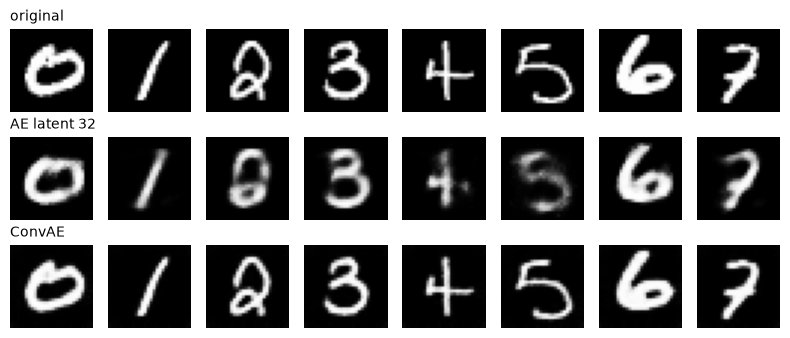

In [15]:
# Conv 오토인코더 (P4 빈칸 정답)
class ConvAE(nn.Module):                                           # 이미지 모양 그대로 다루는 AE
    def __init__(self):                                            # 층 만들기
        super().__init__()                                         # 부모 초기화
        self.encoder = nn.Sequential(                              # 줄이는 쪽 (Conv2d)
            nn.Conv2d(1, 16, 3, stride=2, padding=1), nn.ReLU(),   # →16×14×14
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU())  # →32×7×7
        self.decoder = nn.Sequential(                              # 늘리는 쪽 (ConvTranspose2d)
            nn.ConvTranspose2d(32, 16, 3, stride=2, padding=1,
                               output_padding=1), nn.ReLU(),       # →16×14×14
            nn.ConvTranspose2d(16, 1, 3, stride=2, padding=1,
                               output_padding=1), nn.Sigmoid())    # →1×28×28

    def forward(self, x):                     # model(x)의 길
        return self.decoder(self.encoder(x))  # 펴지도 접지도 않음


# 한 장을 층마다 통과 → 설계 표와 대조
torch.manual_seed(0)                                          # 같은 시작 가중치
cae = ConvAE().to(device)                                     # 학습 전 모델 (모양 확인용)
h = Xte[:1]                                                   # 한 장
for layer in list(cae.encoder) + list(cae.decoder):           # 층을 하나씩
    h = layer(h)                                              # 통과
    if not isinstance(layer, (nn.ReLU, nn.Sigmoid)):          # 모양을 바꾸는 층만 출력
        print(f"{type(layer).__name__:<16}", tuple(h.shape))  # 설계 표와 대조


# 가운데 값 개수 · 파라미터 수 비교
n_cae = sum(p.numel() for p in cae.parameters())               # ConvAE 가중치 개수
n_ae = sum(p.numel() for p in ae32.parameters())               # Dense AE 가중치 개수
print(f"가운데 값  AE 32 | ConvAE {32 * 7 * 7:,} (입력 784)")  # 통로 넓이 비교
print(f"파라미터  AE {n_ae:,} | ConvAE {n_cae:,}")             # 파라미터 비교


# 흔한 실수 ①: 받는 채널을 틀림 → 바로 에러
try:
    nn.ConvTranspose2d(16, 16, 3, 2, 1, output_padding=1)(  # 받는 채널을 16으로 틀림
        torch.zeros(1, 32, 7, 7))
except RuntimeError as e:                                   # 채널 에러를 잡음
    print("실수 ① RuntimeError:", str(e)[-45:])             # 끝부분 = 무엇이 다른지


# 흔한 실수 ②: output_padding 빠뜨림 → 에러 없이 크기만 틀림
miss = nn.Sequential(nn.ConvTranspose2d(32, 16, 3, 2, 1),          # output_padding을 뺀 디코더
                     nn.ConvTranspose2d(16, 1, 3, 2, 1))
print("실수 ② 모양", tuple(miss(torch.zeros(1, 32, 7, 7)).shape))  # 에러 없이 크기만 틀림


# 같은 조건(학습 1만 장 · 5 epoch · seed 0)으로 학습 → 비교
torch.manual_seed(0)                                        # 1-3과 같은 출발점
cae = train(ConvAE().to(device))                            # 1-3 train · 같은 조건
out_cae = run(cae, Xte)                                     # 평가 1만 장 복원
print(f"복원 MSE  AE 32 {mse(run(ae32, Xte)):.4f} | ConvAE {mse(out_cae):.4f}")  # 같은 잣대
show([("original", Xte), ("AE latent 32", run(ae32, Xte)),  # 그림 3줄
      ("ConvAE", out_cae)])

**결과** · 예측 정답은 넓음 — 32 × 7 × 7 = 1568개, 입력의 두 배

- `ConvTranspose2d (1, 1, 28, 28)` — 설계 표와 같음 → 입력과 같은 모양
- `가운데 값 AE 32 | ConvAE 1,568 (입력 784)` — ConvAE의 통로는 입력보다 넓음
- `파라미터 AE 209,968 | ConvAE 9,569` — 약 22분의 1 · 같은 필터를 옮겨 가며 재사용
- `실수 ① RuntimeError: have 16 channels, but got 32 channels instead` — 받는 채널(16) ≠ 들어온 채널(32) → 바로 에러
- `실수 ② 모양 (1, 1, 25, 25)` — output_padding 빠짐 → 에러 없이 7 → 13 → 25
- `복원 MSE AE 32 0.0191 | ConvAE 0.0013` — 같은 조건에서 ConvAE가 훨씬 작음 · 그림도 원본과 거의 구별 안 됨 (AE 32에서 흐렸던 2 · 4 · 5까지)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">Dense AE (<code>Flatten</code> + <code>Linear</code>)</td>
<td style="text-align: left;">그림을 한 줄로 폄 · 이웃 관계를 버림 · 파라미터 많음</td>
<td style="text-align: left;">표 · 신호처럼 이웃 개념이 약한 입력 · 잠재 2차원 시각화</td>
</tr>
<tr>
<td style="text-align: left;">Conv AE (<code>Conv2d</code> + <code>ConvTranspose2d</code>)</td>
<td style="text-align: left;">모양 그대로 · 같은 필터 재사용 · 파라미터 적음</td>
<td style="text-align: left;">이미지 복원 · 노이즈 제거 (미션 5 기본 선택)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - ConvAE의 작은 오차는 통로(1,568)가 입력(784)보다 넓은 덕일 수도 있음
> - 오차만으로 '중요한 것을 더 잘 골랐다'고 말할 수 없음

> ✅ **한 줄 정리** · Conv 오토인코더는 Conv2d로 줄이고 ConvTranspose2d로 되돌리며, 채널 실수는 바로 에러로, 크기 실수는 층마다 찍은 모양으로 잡는다.

**딥러닝 코드에서는**

- 미션 5 요구사항 'Conv2d 인코더 + ConvTranspose2d 디코더 CNN 오토인코더'가 바로 이 구조
- 문서 크기에 맞춰 3-4의 크기 확인을 함께

---
## 4. 종합 실습 · 잠재 크기 3가지 비교 · 2차원 잠재 공간

> **이 장의 흐름**
>
> - 1~3장을 한 번에 사용.
> - 잠재 크기(2-4)만 바꿔 같은 조건으로 학습(1-3)하고, 같은 평가 이미지로 복원을 숫자와 그림으로 비교한 뒤, 잠재 2 모델의 잠재 공간(2-3)을 평면에 직접 그림

**파이프라인 위치** · ③ 학습 → ④ 평가 → ⑤ 설계 선택 → ⑥ 활용

> 🎯 **잠재 크기를 2 · 8 · 32로 바꾸면 복원이 어떻게 달라지고, 2차원 잠재 공간에는 무엇이 보이는가?**

💡 **쉽게 말하면**

- 메모 칸을 2 · 8 · 32칸으로 바꿔 같은 연습을 시킨 뒤 그림 실력을 비교.
- 2칸짜리 메모는 **평면 위 주소**(x, y)라서 1만 장의 주소를 점으로 찍어 볼 수 있음.

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">단계</th>
<th style="text-align: left;">하는 일</th>
<th style="text-align: left;">쓰는 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;">잠재 2 · 8 학습 (32는 1-3 모델 그대로)</td>
<td style="text-align: left;">1-2 <code>AutoEncoder</code> · 1-3 <code>train</code></td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">같은 평가 1만 장으로 복원 MSE · 그림 4줄</td>
<td style="text-align: left;">0장 <code>run</code> · <code>mse</code> · <code>show</code></td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">잠재 2 모델의 좌표 1만 개를 회색으로 → 학습이 끝난 뒤 라벨로 색칠</td>
<td style="text-align: left;">2-3 <code>encoder</code> · <code>yte</code></td>
</tr>
<tr>
<td style="text-align: left;">4</td>
<td style="text-align: left;">숫자별 중심 좌표</td>
<td style="text-align: left;">라벨은 확인용으로만</td>
</tr>
<tr>
<td style="text-align: left;">5</td>
<td style="text-align: left;">찍힌 범위 안 · 범위 밖 멀리에서 좌표를 뽑아 디코더에 넣기</td>
<td style="text-align: left;"><code>decoder</code></td>
</tr>
</tbody>
</table>

**먼저 예측** · 답은 코드 실행 결과 아래에

1. 2 → 8과 8 → 32 중 복원 MSE가 더 많이 줄어드는 쪽은?
2. 라벨을 안 썼는데 같은 숫자끼리 모일까?

잠재 2 학습
  epoch 1  loss 0.0629


  epoch 5  loss 0.0560


  epoch 10  loss 0.0401
잠재 8 학습
  epoch 1  loss 0.0640


  epoch 5  loss 0.0328


  epoch 10  loss 0.0207
잠재  2 | 복원 MSE 0.0512
잠재  8 | 복원 MSE 0.0279
잠재 32 | 복원 MSE 0.0191


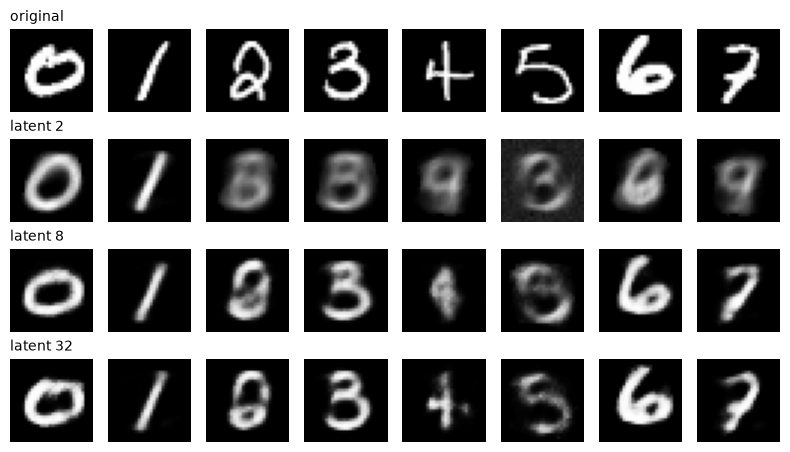

In [16]:
# 잠재 2 · 8 학습 (32는 1-3 모델 그대로 · 모두 같은 조건)
models = {32: ae32}                               # 32는 1-3 모델 재사용
for d in [2, 8]:                                  # 새로 학습할 두 크기
    print(f"잠재 {d} 학습")                       # 어느 모델의 loss인지
    torch.manual_seed(0)                          # 모두 같은 출발점
    models[d] = train(AutoEncoder(d).to(device))  # 같은 조건 · 10 epoch


# 같은 평가 1만 장 · 같은 계산으로 복원 오차 비교
outs = {d: run(models[d], Xte) for d in [2, 8, 32]}                         # 세 모델 복원
for d in [2, 8, 32]:                                                        # 크기 순서로
    print(f"잠재 {d:>2} | 복원 MSE {mse(outs[d]):.4f}")                     # 같은 평가 1만 장
show([("original", Xte)] + [(f"latent {d}", outs[d]) for d in [2, 8, 32]])  # 원본 + 3줄

잠재 좌표 모양 (10000, 2)


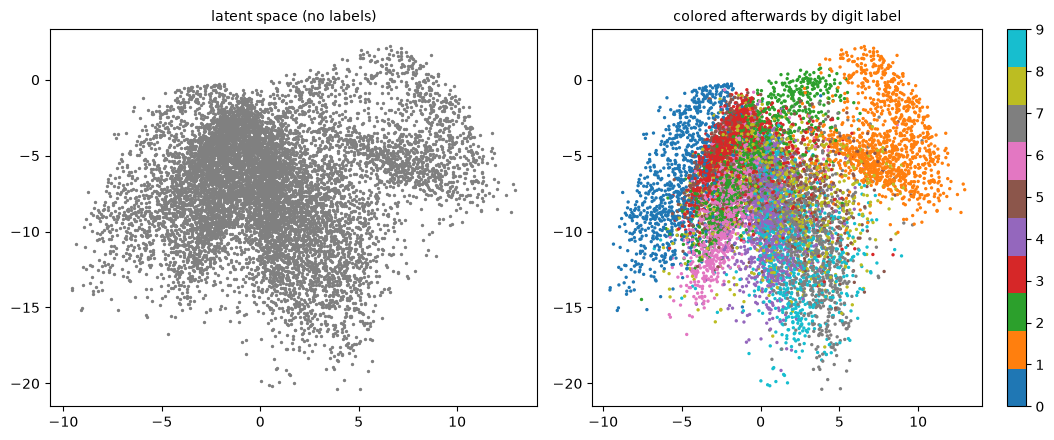

숫자 0 중심 (  -4.9,   -6.5)  숫자 1 중심 (   7.7,   -4.0)
숫자 2 중심 (  -0.5,   -5.3)  숫자 3 중심 (  -1.4,   -4.6)
숫자 4 중심 (   0.5,   -9.0)  숫자 5 중심 (  -0.2,   -6.2)
숫자 6 중심 (  -2.0,   -8.3)  숫자 7 중심 (   2.8,  -10.1)
숫자 8 중심 (   0.9,   -7.2)  숫자 9 중심 (   1.6,  -10.4)
찍힌 범위  x -9.6 ~ 13.0 | y -20.4 ~ 2.2


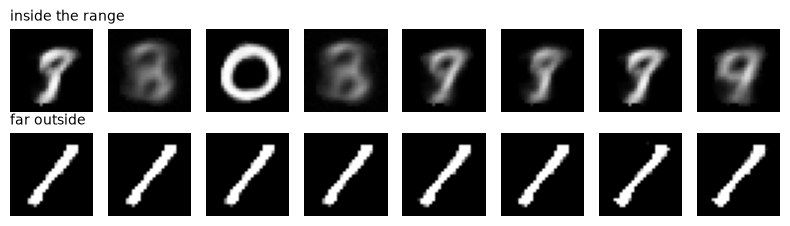

In [17]:
# 잠재 2 모델: 평가 1만 장 → 점 1만 개 (x, y)
with torch.no_grad():                                   # 꺼내기만 (기울기 끔)
    Z2 = torch.cat([models[2].encoder(Xte[i:i + 2000])  # 잠재 2 인코더만 통과
                    for i in range(0, 10000, 2000)]).cpu()
print("잠재 좌표 모양", tuple(Z2.shape))                # (장 수, 2) = 점 1만 개


# 왼쪽: 라벨 없이 회색 / 오른쪽: 학습이 끝난 뒤 라벨로 색만 입힘
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))                    # 왼쪽 회색 · 오른쪽 색칠
axes[0].scatter(Z2[:, 0], Z2[:, 1], s=2, c="gray")                   # 라벨 없이 점만
axes[0].set_title("latent space (no labels)", fontsize=10)           # 왼쪽 제목
sc = axes[1].scatter(Z2[:, 0], Z2[:, 1], s=2, c=yte, cmap="tab10")   # 같은 점에 라벨 색만
axes[1].set_title("colored afterwards by digit label", fontsize=10)  # 학습 뒤 색칠
plt.colorbar(sc, ax=axes[1], ticks=range(10))                        # 색 ↔ 숫자 짝
plt.tight_layout()                                                   # 간격 정리
plt.show()                                                           # 그림 출력


# 숫자별 중심 좌표 (색칠과 같은 정보를 숫자로)
for k in range(0, 10, 2):                                  # 두 숫자씩 한 줄
    a, b = Z2[yte == k].mean(0), Z2[yte == k + 1].mean(0)  # 숫자별 평균 좌표
    print(f"숫자 {k} 중심 ({a[0]:6.1f}, {a[1]:6.1f})  "    # 그림을 숫자로
          f"숫자 {k + 1} 중심 ({b[0]:6.1f}, {b[1]:6.1f})")


# 찍힌 범위 안 · 범위 밖 멀리에서 좌표를 뽑아 디코더에 넣기
torch.manual_seed(1)                                                # 뽑는 좌표 고정
lo, hi = Z2.min(0).values, Z2.max(0).values                         # 축마다 최솟값 · 최댓값
span = hi - lo                                                      # 찍힌 범위의 폭
inside = lo + span * torch.rand(8, 2)                               # 범위 상자 안
outside = hi + span * (0.5 + torch.rand(8, 2))                      # 상자 밖 오른쪽 위
print(f"찍힌 범위  x {lo[0]:.1f} ~ {hi[0]:.1f} | y {lo[1]:.1f} ~ {hi[1]:.1f}")  # 상자 범위
with torch.no_grad():                                               # 생성만 (기울기 끔)
    dec = models[2].decoder                                         # 디코더만 사용
    gen_in = dec(inside.to(device)).reshape(-1, 1, 28, 28).cpu()    # 상자 안 좌표 → 그림
    gen_out = dec(outside.to(device)).reshape(-1, 1, 28, 28).cpu()  # 멀리 밖 좌표 → 그림
fig, axes = plt.subplots(2, 8, figsize=(8, 2.3))                    # 2줄 × 8칸
for c in range(8):                                                  # 칸마다
    for r, G in enumerate([gen_in, gen_out]):                       # 윗줄 안 · 아랫줄 밖
        axes[r, c].imshow(G[c, 0], cmap="gray", vmin=0, vmax=1)     # 밝기 0~1 고정
        axes[r, c].axis("off")                                      # 눈금 숨김
axes[0, 0].set_title("inside the range", loc="left", fontsize=10)   # 윗줄 이름
axes[1, 0].set_title("far outside", loc="left", fontsize=10)        # 아랫줄 이름
plt.tight_layout()                                                  # 간격 정리
plt.show()                                                          # 그림 출력

**결과** · 예측 정답은 ① **2 → 8**이 훨씬 많이 줄어듦 ② 일부 숫자만 따로 모임

- ① 2 → 8은 0.0512 → 0.0279 (0.0233 감소) · 8 → 32는 0.0088 감소 → 아주 좁은 통로를 넓힐 때 효과가 가장 큼
- ② 0 · 1 · 2는 따로 모이고 4 · 7 · 9는 겹침

- `잠재 2 | 복원 MSE 0.0512` — 가장 흐림 · 0 · 1만 또렷 · 2 · 3은 8처럼, 4 · 7은 9처럼 다른 숫자 모양
- `잠재 8 | 복원 MSE 0.0279` — 2 → 8에서 오차가 거의 반 · 7은 돌아오고 2는 아직 8처럼, 4는 덩어리
- `잠재 32 | 복원 MSE 0.0191` — 8 → 32는 줄어드는 폭이 작음 · 4가 십자 모양으로 돌아옴
- `잠재 좌표 모양 (10000, 2)` — 평가 1만 장 = 평면 위 점 1만 개
- `숫자 0 중심 ( -4.9, -6.5) 숫자 1 중심 ( 7.7, -4.0)` — 0(파랑)은 왼쪽, 1(주황)은 오른쪽 · 2(초록)는 위쪽 가운데
- `숫자 4 중심 ( 0.5, -9.0) 숫자 5 중심 ( -0.2, -6.2)` — 4 · 7 · 9는 아래쪽 띠에서 뒤섞임 → 잠재 2에서 9처럼 복원된 이유
- `찍힌 범위 x -9.6 ~ 13.0 | y -20.4 ~ 2.2` — 상자 안 8점은 9 · 8 · 0처럼 보임 · 상자 밖 멀리 8점은 모두 같은 굵은 사선 획

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">잠재 2</td>
<td style="text-align: left;">복원은 가장 흐리지만 <strong>평면에 그대로 그려짐</strong></td>
<td style="text-align: left;">잠재 공간을 눈으로 볼 때 · 시각화</td>
</tr>
<tr>
<td style="text-align: left;">잠재 8</td>
<td style="text-align: left;">2보다 훨씬 선명 · 일부 숫자 모양은 아직 바뀜</td>
<td style="text-align: left;">강한 압축이 필요할 때</td>
</tr>
<tr>
<td style="text-align: left;">잠재 32</td>
<td style="text-align: left;">셋 중 가장 선명 · 그림으로는 못 그림 (축 32개)</td>
<td style="text-align: left;">복원 품질이 중요할 때 · 기본값</td>
</tr>
<tr>
<td style="text-align: left;">찍힌 범위 안에서 좌표 뽑기</td>
<td style="text-align: left;">디코더가 본 적 있는 근처 → 숫자처럼 보임</td>
<td style="text-align: left;">새 그림을 만들어 볼 때 (어디서 뽑을지는 산점도를 보고)</td>
</tr>
<tr>
<td style="text-align: left;">범위 밖 멀리에서 좌표 뽑기</td>
<td style="text-align: left;">학습에서 본 적 없는 자리 → 의미 없는 같은 모양</td>
<td style="text-align: left;">쓰면 안 됨 · VAE가 이 문제를 다룸 (오토인코더-2)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 이번 결과는 MNIST · 이 구조 · 학습 1만 장 · 10 epoch · seed 0 한 번의 실행
> - 잠재 공간의 축에는 사람이 붙인 뜻이 없음

> ✅ **한 줄 정리** · 잠재 크기는 좁을수록 흐려지고 넓힐수록 선명해지되 좁은 쪽을 넓힐 때 효과가 가장 크며, 라벨 없이 배운 2차원 잠재 공간에서도 일부 숫자는 따로 모인다.

**딥러닝 코드에서는**

- 잠재 크기를 고를 때 이 실습처럼 **하나만 바꿔** 같은 조건 · 같은 평가 이미지로 숫자와 그림을 함께 비교
- 오토인코더-2 4장 '하나만 바꾸기'의 출발점

---
## 그래서 오늘 무엇을 배웠는가?

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">학습 목표</th>
<th style="text-align: left;">할 수 있게 된 것</th>
<th style="text-align: left;">확인 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1. 라벨 없이 배우기</td>
<td style="text-align: left;">정답 자리에 입력 · 베끼면 loss 0 · 32칸으로 좁혀야 배움</td>
<td style="text-align: left;">1-1 · 1-3</td>
</tr>
<tr>
<td style="text-align: left;">2. 층별 모양</td>
<td style="text-align: left;">784 → 128 → 16 → 128 → 784 손계산을 층마다 찍어 대조</td>
<td style="text-align: left;">1-2</td>
</tr>
<tr>
<td style="text-align: left;">3. 설계 선택</td>
<td style="text-align: left;">Sigmoid · MSE vs BCE · 잠재 크기 · PCA(0.0170 &lt; 0.0191)를 같은 조건으로 비교</td>
<td style="text-align: left;">2장</td>
</tr>
<tr>
<td style="text-align: left;">4. 크기 맞추기</td>
<td style="text-align: left;">30 → 15 → 8 → 16 → 32를 찾고 <code>out[..., :h, :w]</code>로 맞춤 · 버그판 padding 한 곳 수정</td>
<td style="text-align: left;">3-3 · 3-4</td>
</tr>
<tr>
<td style="text-align: left;">5. 잠재 공간 해석</td>
<td style="text-align: left;">잠재 2 · 8 · 32 오차 0.0512 · 0.0279 · 0.0191 · 0과 1은 따로, 4 · 7 · 9는 겹침</td>
<td style="text-align: left;">4장</td>
</tr>
</tbody>
</table>

### 주제별 한 줄 · 반드시 기억할 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">등급</th>
<th style="text-align: left;">주제</th>
<th style="text-align: left;">반드시 기억할 것</th>
<th style="text-align: left;">딥러닝 코드에서</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">입력이 곧 정답</td>
<td style="text-align: left;">정답 자리에 입력 · 가운데를 좁힘</td>
<td style="text-align: left;"><code>F.mse_loss(model(x), x)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">인코더 · 디코더</td>
<td style="text-align: left;">784 → 잠재 → 784 · 디코더 첫 층 = 잠재 크기</td>
<td style="text-align: left;"><code>self.encoder</code> · <code>self.decoder</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">학습 루프</td>
<td style="text-align: left;">zero_grad → backward() → step()</td>
<td style="text-align: left;">분류 루프와 같은 모양</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">버그 찾기</td>
<td style="text-align: left;">에러 없이 이상하면 입력 · 정답 짝부터</td>
<td style="text-align: left;">그림을 원본과 한 열씩</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">끝 함수</td>
<td style="text-align: left;">0~1 입력이면 Sigmoid</td>
<td style="text-align: left;">정규화 방식과 짝지어 확인</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">잠재 공간 · 크기</td>
<td style="text-align: left;">비슷한 그림끼리 가까움 · 크기는 설계 선택</td>
<td style="text-align: left;"><code>latent_dim</code> 하나만 바꿔 비교</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">Conv2d · ConvTranspose2d</td>
<td style="text-align: left;">k3 s2 p1 → 반 · + op1 → 두 배</td>
<td style="text-align: left;">줄 끝에 크기 주석</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">크기 맞추기</td>
<td style="text-align: left;">층마다 찍어 처음 어긋난 층 · 2ⁿ의 배수</td>
<td style="text-align: left;"><code>out[..., :h, :w]</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">Conv AE</td>
<td style="text-align: left;">이미지는 Conv AE · 통로 넓이와 함께 읽기</td>
<td style="text-align: left;">미션 5 모델 구조</td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">MSE vs BCE</td>
<td style="text-align: left;">눈금이 다름 · BCE는 0~1 필수</td>
<td style="text-align: left;">평가는 같은 지표로</td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">오토인코더 vs PCA</td>
<td style="text-align: left;">비선형 · 학습 vs 선형 · 계산</td>
<td style="text-align: left;">PCA를 기준선으로</td>
</tr>
</tbody>
</table>

---
## 기억 확인 문제

위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시. △ · ×인 섹션만 다시 보기.

### 1. 질문에 답하기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">🎯 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-1</td>
<td style="text-align: left;">라벨이 없으면 무엇을 정답으로 두고, 왜 가운데를 좁히는가?</td>
</tr>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;">디코더 첫 <code>nn.Linear</code>는 값을 몇 개 받아야 하는가?</td>
</tr>
<tr>
<td style="text-align: left;">1-4</td>
<td style="text-align: left;">에러 없이 결과가 이상하면 무엇부터 확인하는가?</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">디코더 끝에 Sigmoid를 두는 이유는?</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;">MSE 모델과 BCE 모델을 loss 숫자로 비교하면 안 되는 이유는?</td>
</tr>
<tr>
<td style="text-align: left;">2-4</td>
<td style="text-align: left;">잠재 크기는 어떻게 고르는가?</td>
</tr>
<tr>
<td style="text-align: left;">2-5</td>
<td style="text-align: left;">오토인코더와 PCA는 무엇이 다른가?</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;">Conv2d k3 s2 p1에 15를 넣으면 몇이 나오는가?</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">ConvTranspose2d로 딱 두 배를 만드는 설정 두 가지는?</td>
</tr>
<tr>
<td style="text-align: left;">3-4</td>
<td style="text-align: left;">30×30이 32×32로 돌아오는 이유와 해결은?</td>
</tr>
<tr>
<td style="text-align: left;">3-5</td>
<td style="text-align: left;">ConvAE의 오차가 작다고 더 좋은 모델이라 말하기 어려운 이유는?</td>
</tr>
<tr>
<td style="text-align: left;">4</td>
<td style="text-align: left;">라벨 없이 배운 2차원 잠재 공간에서 본 것은?</td>
</tr>
</tbody>
</table>

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-5** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-5** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 2. 코드로 답하기

아래 빈 셀에 직접 작성 후 실행.

1. 잠재 크기 10인 인코더(`Flatten` → `Linear(784, 128)` → `ReLU` → `Linear(128, 10)`)에 한 장을 넣었을 때 **잠재 벡터 모양**
2. 3-1 공식으로 30을 `Conv2d(k3, s2, p1)`에 **두 번** 넣은 크기 두 개
3. `ConvTranspose2d(k3, s2, p1, output_padding=1)`에 7×7을 넣은 **출력 크기**
4. 50×50을 줄이기 2번 · 늘리기 2번(딱 두 배) 모델에 넣으면 나오는 크기와, 원래 크기로 **잘라낸 모양**

In [18]:
# 코드 문제 직접 작성

### 3. 변형 문제 · 조건을 바꿔 다시 풀기

1. 잠재 4인 `AutoEncoder`의 파라미터 수를 2-4의 방법으로 먼저 손으로 구하고 코드로 확인
2. 3-4의 `tiny` 모델에 60×60과 62×62를 넣으면 출력 크기는 각각? 표로 먼저 따라간 뒤 실행
3. 3-5 ConvAE 인코더 마지막 Conv2d의 채널을 8로 바꾸면 가운데 값 개수는? 디코더에서 함께 바꿀 곳은?

In [19]:
# 변형 문제 직접 작성

### 4. 모범 답안 · 1 ~ 3을 다 푼 뒤에 보기

#### 질문 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-1</td>
<td style="text-align: left;">입력 자신. 가운데가 넓으면 그대로 베껴 배울 것이 없어서 좁혀 무엇을 남길지 고르게 함</td>
</tr>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;">잠재 크기(<code>latent_dim</code>)개 = 인코더가 마지막에 내놓은 개수</td>
</tr>
<tr>
<td style="text-align: left;">1-4</td>
<td style="text-align: left;">손실의 입력 · 정답 자리가 같은 이미지의 짝인지. 그림을 원본과 한 열씩 맞대어 봄</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">입력이 0~1이라 출력도 0~1에 넣으려고. 없으면 0~1 밖 값이 섞임</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;">손실마다 눈금이 달라서. 같은 평가 지표(평가 MSE)로 재야 함</td>
</tr>
<tr>
<td style="text-align: left;">2-4</td>
<td style="text-align: left;">크기 하나만 바꿔 같은 조건으로 학습하고 같은 평가 이미지로 숫자 · 그림을 비교</td>
</tr>
<tr>
<td style="text-align: left;">2-5</td>
<td style="text-align: left;">PCA는 선형 · 계산 한 번, 오토인코더는 비선형 · 학습. 이번 조건에서는 PCA가 조금 나았음</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;">8 (홀수는 반을 올림)</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">k3 s2 p1 + <code>output_padding=1</code>, 또는 k4 s2 p1 (Upsample + Conv도 가능)</td>
</tr>
<tr>
<td style="text-align: left;">3-4</td>
<td style="text-align: left;">15가 홀수라 8로 올림 → 16 → 32. 출력을 <code>[..., :30, :30]</code>으로 잘라내거나 4의 배수로 채워 넣음</td>
</tr>
<tr>
<td style="text-align: left;">3-5</td>
<td style="text-align: left;">가운데 값(1,568)이 입력(784)보다 넓어 베끼기에 가까울 수 있고, 한 번의 실행이라서</td>
</tr>
<tr>
<td style="text-align: left;">4</td>
<td style="text-align: left;">0 · 1은 따로 모이고 4 · 7 · 9는 겹침. 찍힌 범위 안 좌표는 숫자처럼, 멀리 밖은 모두 같은 굵은 사선 획</td>
</tr>
</tbody>
</table>

#### 코드 문제 답

```python
import torch
import torch.nn as nn

# 1. 잠재 10 → (1, 10)
enc = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(),
                    nn.Linear(128, 10))
print(tuple(enc(torch.zeros(1, 1, 28, 28)).shape))  # (1, 10)


# 2. (n + 2p - k) // s + 1 을 두 번
def conv_out(n, k=3, s=2, p=1):
    return (n + 2 * p - k) // s + 1


print(conv_out(30), conv_out(conv_out(30)))  # 15 8

# 3. (7 - 1) × 2 - 2 + 3 + 1
up = nn.ConvTranspose2d(1, 1, 3, stride=2, padding=1, output_padding=1)
print(up(torch.zeros(1, 1, 7, 7)).shape[-1])  # 14

# 4. 50 → 25 → 13 → 26 → 52 → 잘라내기
tiny = nn.Sequential(nn.Conv2d(1, 4, 3, 2, 1), nn.Conv2d(4, 4, 3, 2, 1),
                     nn.ConvTranspose2d(4, 4, 4, 2, 1),
                     nn.ConvTranspose2d(4, 1, 4, 2, 1))
out = tiny(torch.zeros(1, 1, 50, 50))
print(tuple(out.shape))  # (1, 1, 52, 52)
print(tuple(out[..., :50, :50].shape))  # (1, 1, 50, 50)
```

#### 변형 문제 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">문제</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;">바뀌는 두 층 128 × 4 + 4 + 4 × 128 + 128 = 1156 · 전체 202,772개 (잠재 2의 202,258보다 514개 많음)</td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">60 → 30 → 15 → 30 → 60 (그대로) · 62 → 31 → 16 → 32 → 64 (2칸 큼, 31이 홀수)</td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">8 × 7 × 7 = 392개 (입력 784의 반) · 디코더 첫 <code>ConvTranspose2d(8, 16, …)</code>로 받는 채널도 8</td>
</tr>
</tbody>
</table>

---
## 오답 노트

틀린 문제는 정답을 베끼지 말고 **원인**을 적음. 다음 복습 때 "재발 방지 질문"부터 스스로에게 물어보기.

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">틀린 내용</th>
<th style="text-align: left;">틀린 이유</th>
<th style="text-align: left;">올바른 원칙</th>
<th style="text-align: left;">재발 방지 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">(예) 30×30이 그대로 돌아온다고 답함</td>
<td style="text-align: left;">반으로 줄일 때 홀수 올림을 빠뜨림</td>
<td style="text-align: left;">줄이기 n번이면 2ⁿ의 배수일 때만 그대로</td>
<td style="text-align: left;">줄일 때마다 짝수 · 홀수를 따라갔나?</td>
</tr>
<tr>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
</tr>
<tr>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
</tr>
</tbody>
</table>

---
## 면접 30초 답변

**Q1. 오토인코더는 라벨이 없는데 어떻게 학습하나요?**
> - 정답 자리에 입력 자신을 둡니다.
> - 인코더가 입력을 작은 잠재 벡터로 줄이고 디코더가 다시 되돌린 결과를 입력과 MSE로 비교해 그 차이를 줄이도록 학습합니다.
> - 가운데를 좁혀 두었기 때문에 그대로 베낄 수 없고, 복원에 꼭 필요한 정보를 골라 남기게 됩니다.

**Q2. 잠재 공간의 크기는 어떻게 정하나요?**
> - 정답이 있는 값이 아니라 설계 선택입니다.
> - 좁히면 흐려지고 다른 모양이 나오기도 하며, 넓히면 복원은 좋아지지만 베끼기에 가까워집니다.
> - 그래서 크기 하나만 바꿔 같은 조건으로 몇 개를 학습하고, 같은 평가 데이터에서 복원 오차와 그림을 함께 비교해 고릅니다.

**Q3. Conv 오토인코더의 출력 크기가 입력과 다르게 나오면 어떻게 하나요?**
> - 먼저 층마다 나올 크기를 표로 적고, 입력 한 장을 층마다 통과시켜 찍힌 모양과 대조해 처음 어긋난 층을 찾습니다.
> - 보통 홀수 크기가 stride 2 층에 들어가 올림이 생기거나 output_padding이 빠진 경우입니다.
> - 입력 크기가 문제면 4의 배수로 채워 넣고 출력을 원래 크기로 잘라냅니다.

**Q4. 오토인코더와 PCA는 무엇이 다른가요?**
> - PCA는 분산이 큰 축을 계산으로 한 번에 찾는 선형 압축이고, 오토인코더는 활성화 함수가 있는 신경망으로 학습하는 비선형 압축입니다.
> - 데이터가 적고 학습이 짧으면 PCA가 더 나을 수도 있어서, 오토인코더를 쓸 때는 PCA를 기준선으로 함께 비교합니다.

---
## 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
<th style="text-align: left;">코드에서 사용한 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>nn.Identity()</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">입력을 그대로 내보냄 (베끼기 비교용)</td>
<td style="text-align: left;">1-1 <code>copy = nn.Identity()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Sequential</code> · <code>nn.Flatten</code> · <code>nn.Unflatten</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">층 이어 붙이기 · 펴기 · 다시 접기</td>
<td style="text-align: left;">1-1 <code>narrow = nn.Sequential(</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Linear</code> · <code>nn.ReLU</code> · <code>nn.Sigmoid</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">완전 연결 · 활성화 · 0~1로 누르기</td>
<td style="text-align: left;">1-2 <code>nn.Linear(784, 128), nn.ReLU(),</code> · <code>nn.Linear(128, 784), nn.Sigmoid())</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>F.mse_loss(model(x), x)</code></td>
<td style="text-align: left;">torch.nn.functional</td>
<td style="text-align: left;">복원 오차 (정답 = 입력)</td>
<td style="text-align: left;">1-3 <code>loss = loss_fn(model(x), x)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>opt.zero_grad()</code> · <code>loss.backward()</code> · <code>opt.step()</code></td>
<td style="text-align: left;">torch.optim · Tensor</td>
<td style="text-align: left;">기울기 비우기 · 계산 · 갱신</td>
<td style="text-align: left;">1-3 <code>opt.zero_grad()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.randperm</code> · <code>torch.manual_seed</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">번호 섞기 · 재현성</td>
<td style="text-align: left;">1-3 <code>perm = torch.randperm(len(Xtr), device=device)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>@torch.no_grad()</code> · <code>model.eval()</code></td>
<td style="text-align: left;">torch · nn.Module</td>
<td style="text-align: left;">결과만 볼 때</td>
<td style="text-align: left;">0 <code>@torch.no_grad()</code> · <code>model.eval()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Sigmoid</code> · <code>clamp(0, 1)</code></td>
<td style="text-align: left;">torch.nn · Tensor</td>
<td style="text-align: left;">출력을 0~1로 · 그릴 때만 자르기</td>
<td style="text-align: left;">1-2 <code>nn.Linear(128, 784), nn.Sigmoid())</code> · 2-5 <code>out_pca.clamp(0, 1)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>F.binary_cross_entropy</code></td>
<td style="text-align: left;">torch.nn.functional</td>
<td style="text-align: left;">0~1 출력용 BCE 손실</td>
<td style="text-align: left;">2-2 <code>ae_bce = train(AutoEncoder(32).to(device), loss_fn…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>model.encoder(x)</code></td>
<td style="text-align: left;">nn.Module (내가 만든 속성)</td>
<td style="text-align: left;">잠재 벡터 꺼내기</td>
<td style="text-align: left;">2-3 <code>ae32.encoder(Xte[i:i + 2000])</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.cdist</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">점들 사이 거리 한꺼번에</td>
<td style="text-align: left;">2-3 <code>D = torch.cdist(A[idx], A[idx])</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>p.numel()</code> · <code>model.parameters()</code></td>
<td style="text-align: left;">Tensor · nn.Module</td>
<td style="text-align: left;">파라미터 수 세기</td>
<td style="text-align: left;">2-4 <code>sum(p.numel() for p in AutoEncoder(d).parameters())</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>PCA(n_components)</code> · <code>transform</code> · <code>inverse_transform</code></td>
<td style="text-align: left;">sklearn.decomposition</td>
<td style="text-align: left;">선형 압축 · 복원 (기준선)</td>
<td style="text-align: left;">2-5 <code>pca = PCA(n_components=32, random_state=0).fit(Xtr…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Conv2d(in, out, k, stride, padding)</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">줄이기 (k3 s2 p1 → 반)</td>
<td style="text-align: left;">3-1 <code>down = nn.Conv2d(1, 1, kernel_size=3, stride=2, pa…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.ConvTranspose2d(..., output_padding)</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">늘리기 (k3 s2 p1 op1 → 두 배)</td>
<td style="text-align: left;">3-2 <code>"ConvT k3 s2 p1": nn.ConvTranspose2d(16, 8, 3, 2, …</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Upsample(scale_factor=2)</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">보간으로 키우기 (가중치 없음)</td>
<td style="text-align: left;">3-2 <code>nn.Upsample(scale_factor=2), nn.Conv2d(16, 8, 3, p…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.MaxPool2d(2)</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">최댓값으로 줄이기 (비교용)</td>
<td style="text-align: left;">— (3-1 비교표에서만 설명)</td>
</tr>
<tr>
<td style="text-align: left;"><code>for layer in model:</code></td>
<td style="text-align: left;">Python 기본 문법 · nn.Sequential</td>
<td style="text-align: left;">층마다 통과시키며 모양 찍기</td>
<td style="text-align: left;">3-3 <code>for layer in model:</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>out[..., :h, :w]</code></td>
<td style="text-align: left;">Tensor 인덱싱</td>
<td style="text-align: left;">원래 크기만 잘라내기</td>
<td style="text-align: left;">3-4 <code>out = tiny(x30)[..., :30, :30]</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>try</code> · <code>except RuntimeError</code></td>
<td style="text-align: left;">Python 기본 문법</td>
<td style="text-align: left;">일부러 낸 에러를 잡아 메시지 읽기</td>
<td style="text-align: left;">3-4 <code>except RuntimeError as e:</code></td>
</tr>
</tbody>
</table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">✅ 할 것</th>
<th style="text-align: left;">⚠️ 하지 말 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">치기 전에 층마다 크기 표</td>
<td style="text-align: left;">마지막 출력 모양만 확인</td>
</tr>
<tr>
<td style="text-align: left;">한 장을 층마다 통과시켜 모양 찍기</td>
<td style="text-align: left;">다른 층을 바꿔 크기만 맞추기</td>
</tr>
<tr>
<td style="text-align: left;">그림을 원본과 한 열씩 맞대어 보기</td>
<td style="text-align: left;">loss가 내려간다고 정상이라 믿기</td>
</tr>
<tr>
<td style="text-align: left;">모델 비교는 같은 평가 이미지 · 같은 지표</td>
<td style="text-align: left;">손실 종류가 다른 loss끼리 비교</td>
</tr>
<tr>
<td style="text-align: left;">seed · 조건을 고정하고 하나만 바꾸기</td>
<td style="text-align: left;">오차가 작다고 무조건 좋은 모델로 단정</td>
</tr>
</tbody>
</table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">짝</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">결론</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">지도 학습 vs 오토인코더</td>
<td style="text-align: left;">정답이 라벨 vs 정답이 입력 자신</td>
<td style="text-align: left;">라벨이 없으면 정답 자리에 입력</td>
</tr>
<tr>
<td style="text-align: left;">인코더 vs 디코더</td>
<td style="text-align: left;">줄이기 vs 되돌리기</td>
<td style="text-align: left;">디코더 첫 층 입력 = 잠재 크기</td>
</tr>
<tr>
<td style="text-align: left;">Sigmoid 있음 vs 없음</td>
<td style="text-align: left;">출력 0~1 고정 vs 범위 자유</td>
<td style="text-align: left;">입력 범위에 맞춰 끝 함수 선택</td>
</tr>
<tr>
<td style="text-align: left;">MSE vs BCE</td>
<td style="text-align: left;">차이² 평균 vs 확률 로그 손실 (0~1 필수)</td>
<td style="text-align: left;">비교는 같은 평가 지표로</td>
</tr>
<tr>
<td style="text-align: left;">잠재 작게 vs 크게</td>
<td style="text-align: left;">강한 요약 · 흐림 vs 선명 · 베끼기에 가까움</td>
<td style="text-align: left;">같은 조건으로 몇 개 학습해 고름</td>
</tr>
<tr>
<td style="text-align: left;">오토인코더 vs PCA</td>
<td style="text-align: left;">비선형 · 학습 vs 선형 · 계산 한 번</td>
<td style="text-align: left;">PCA를 기준선으로 함께 잼</td>
</tr>
<tr>
<td style="text-align: left;">Dense AE vs Conv AE</td>
<td style="text-align: left;">한 줄로 폄 vs 모양 그대로</td>
<td style="text-align: left;">이미지는 Conv AE</td>
</tr>
<tr>
<td style="text-align: left;">Conv2d vs ConvTranspose2d vs Upsample+Conv</td>
<td style="text-align: left;">줄이기 vs 벌려서 늘리기 vs 보간 후 다듬기</td>
<td style="text-align: left;">늘릴 땐 공식으로 두 배인지 확인</td>
</tr>
<tr>
<td style="text-align: left;"><code>padding</code> vs <code>output_padding</code></td>
<td style="text-align: left;">입력 가장자리 덧대기 vs 출력 크기 한 칸 추가</td>
<td style="text-align: left;">op는 ConvTranspose2d에만</td>
</tr>
<tr>
<td style="text-align: left;">채널 틀림 vs 크기 틀림</td>
<td style="text-align: left;">바로 에러 vs 에러 없이 진행</td>
<td style="text-align: left;">크기는 층마다 찍어서 확인</td>
</tr>
</tbody>
</table>

---
## 다음 복습일

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">언제</th>
<th style="text-align: left;">할 일</th>
<th style="text-align: left;">걸리는 시간</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">내일</td>
<td style="text-align: left;">기억 확인 문제 1을 자료 없이 다시 답하고 오답 노트 갱신</td>
<td style="text-align: left;">15분</td>
</tr>
<tr>
<td style="text-align: left;">3일 뒤</td>
<td style="text-align: left;">변형 문제 3개를 새로 풀기 · 3-4 손계산표를 가리고 다시 채우기</td>
<td style="text-align: left;">20분</td>
</tr>
<tr>
<td style="text-align: left;">7일 뒤</td>
<td style="text-align: left;">3-5 ConvAE를 직접 다시 짜서 층별 모양을 먼저 손으로 적고 실행</td>
<td style="text-align: left;">30분</td>
</tr>
<tr>
<td style="text-align: left;">14일 뒤</td>
<td style="text-align: left;">오답 노트에 남은 문제만 다시 풀기 · 오토인코더-2 시작 전 1 · 3장 ✅ 줄만 읽기</td>
<td style="text-align: left;">15분</td>
</tr>
</tbody>
</table>

---
## 부록

### 이 노트북을 만든 방법

- 정답(라벨) 없이 입력만으로 배우는 오토인코더를 **3개 대단원 · 14개 섹션**으로 정리.
- 코드잇 개념 PDF
- 1일차 강의(225쪽) · 실습 P1 · P2 · P2_BUG · P3
- P4의 빈칸을 모두 채워 실행으로 검증하고, 마지막 **종합 실습**에서 잠재 크기 3가지와 2차원 잠재 공간을 비교.
- 데이터는 torchvision MNIST(학습 1만 장 · 평가 1만 장).

### 읽는 법

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">표시</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>A</code> · <code>B</code></td>
<td style="text-align: left;"><strong>A</strong> 딥러닝 코드에 바로 나오는 필수 · <strong>B</strong> 알아두면 되는 것</td>
</tr>
<tr>
<td style="text-align: left;">🎯</td>
<td style="text-align: left;">이번 섹션에서 답해야 할 질문</td>
</tr>
<tr>
<td style="text-align: left;">💡</td>
<td style="text-align: left;">쉬운 설명 · 비유</td>
</tr>
<tr>
<td style="text-align: left;">⚠️</td>
<td style="text-align: left;">자주 하는 실수</td>
</tr>
<tr>
<td style="text-align: left;">✅</td>
<td style="text-align: left;">기억할 결론 = 🎯 질문의 답</td>
</tr>
<tr>
<td style="text-align: left;">보강</td>
<td style="text-align: left;">수업 자료에 없어 따로 보탠 내용</td>
</tr>
</tbody>
</table>

**섹션 구성** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → (손계산 표) → 먼저 예측 → 코드 → 결과 (예측 정답 · 출력 줄) → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리

**코드 주석** · 코드 위 = 이 단계에서 하는 일, 코드 옆 = 실행 흐름 · 모양 변화

**실행 환경** · 결과 수치는 이 PC(GPU)에서 seed 0으로 실행한 값. 두 번 실행해 같은 값임을 확인했고, CPU에서는 소수 넷째 자리가 조금 다를 수 있음

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">원본</th>
<th style="text-align: left;">섹션</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">코드잇 PDF p3–15 · 차원 축소 · 표현 학습 · 오토인코더 정의</td>
<td style="text-align: left;">1-1 · 2-3 · 2-5</td>
</tr>
<tr>
<td style="text-align: left;">코드잇 PDF p17–26 · 인코더 · 디코더 · 학습 과정</td>
<td style="text-align: left;">1-2 · 1-3</td>
</tr>
<tr>
<td style="text-align: left;">day01 p1–19 · 정답이 따로 없는 과제 · 병목</td>
<td style="text-align: left;">1-1</td>
</tr>
<tr>
<td style="text-align: left;">day01 p20–41 + <strong>P1</strong> (크기 표 · 인코더 · 디코더 빈칸)</td>
<td style="text-align: left;">1-2</td>
</tr>
<tr>
<td style="text-align: left;">day01 p42–67 + <strong>P2</strong> (학습 루프 빈칸)</td>
<td style="text-align: left;">1-3</td>
</tr>
<tr>
<td style="text-align: left;"><strong>P2_BUG</strong> (버그 찾기)</td>
<td style="text-align: left;">1-4</td>
</tr>
<tr>
<td style="text-align: left;">day01 p36–37 · 마지막 Sigmoid</td>
<td style="text-align: left;">2-1</td>
</tr>
<tr>
<td style="text-align: left;">day01 p58 · p62–63 · p100–132 · 잠재 벡터 · 2차원 좌표</td>
<td style="text-align: left;">2-3 · 4장</td>
</tr>
<tr>
<td style="text-align: left;">day01 p72–97 · 통로 크기</td>
<td style="text-align: left;">2-4 · 4장</td>
</tr>
<tr>
<td style="text-align: left;">day01 p134–160 · Conv2d · ConvTranspose2d</td>
<td style="text-align: left;">3-1 · 3-2</td>
</tr>
<tr>
<td style="text-align: left;">day01 p170–172 + <strong>P3</strong> (크기 표 · 어긋난 층)</td>
<td style="text-align: left;">3-3</td>
</tr>
<tr>
<td style="text-align: left;">day01 p161–168 · 여러 크기 넣기</td>
<td style="text-align: left;">3-4</td>
</tr>
<tr>
<td style="text-align: left;">day01 p173–216 + <strong>P4</strong> (Conv 디코더 빈칸)</td>
<td style="text-align: left;">3-5</td>
</tr>
<tr>
<td style="text-align: left;">보강 · MSE vs BCE · 오토인코더 vs PCA</td>
<td style="text-align: left;">2-2 · 2-5</td>
</tr>
<tr>
<td style="text-align: left;">미션 5 안내 (day01 p2–3 · p137 · p215 · p223) · 코드잇 p28–29 (노이즈 제거 활용)</td>
<td style="text-align: left;">제외 · 노이즈 제거는 오토인코더-2</td>
</tr>
</tbody>
</table>

### 실습 빈칸 정답표 · 31칸 (코드 22 · 표 9)

모든 빈칸을 아래 정답으로 채운 코드를 해당 섹션에서 실행해 검증 (원본 실습 파일은 수정하지 않음)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">실습</th>
<th style="text-align: left;">빈칸</th>
<th style="text-align: left;">정답</th>
<th style="text-align: left;">검증 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">P1 코드 (10칸)</td>
<td style="text-align: left;"><code>LATENT</code> · Linear 숫자 8개 · 끝 함수</td>
<td style="text-align: left;"><code>16</code> · <code>(784, 128)</code> <code>(128, latent_dim)</code> · <code>(latent_dim, 128)</code> <code>(128, 784)</code> · <code>nn.Sigmoid()</code></td>
<td style="text-align: left;">1-2 코드</td>
</tr>
<tr>
<td style="text-align: left;">P1 표 (3칸)</td>
<td style="text-align: left;">Flatten 뒤 · 잠재 벡터 · 복원</td>
<td style="text-align: left;"><code>(1, 784)</code> · <code>(1, 16)</code> · <code>(1, 1, 28, 28)</code></td>
<td style="text-align: left;">1-2 손계산 표 · 출력</td>
</tr>
<tr>
<td style="text-align: left;">P2 코드 (4칸)</td>
<td style="text-align: left;">손실 두 자리 · 기울기 · 갱신</td>
<td style="text-align: left;"><code>F.mse_loss(model(x), x)</code> · <code>loss.backward()</code> · <code>opt.step()</code></td>
<td style="text-align: left;">1-3 코드</td>
</tr>
<tr>
<td style="text-align: left;">P2_BUG (빈칸 없음)</td>
<td style="text-align: left;">버그 줄 찾기</td>
<td style="text-align: left;"><code>y = Xtr[other[...]]</code> → 정답 자리를 <code>x</code>로</td>
<td style="text-align: left;">1-4</td>
</tr>
<tr>
<td style="text-align: left;">P3 표 (6칸)</td>
<td style="text-align: left;">나오는 · 들어가는 크기</td>
<td style="text-align: left;">14 → 14, 7 → 7, 14 → 14</td>
<td style="text-align: left;">3-3 손계산 표</td>
</tr>
<tr>
<td style="text-align: left;">P3 코드 (3칸)</td>
<td style="text-align: left;"><code>표 = [__, __, __, 28]</code></td>
<td style="text-align: left;"><code>[14, 7, 14, 28]</code> · 고칠 곳 2번째 Conv2d <code>padding=0 → 1</code></td>
<td style="text-align: left;">3-3 코드 · 출력</td>
</tr>
<tr>
<td style="text-align: left;">P4 코드 (5칸)</td>
<td style="text-align: left;">채널 숫자 4개 · 끝 함수</td>
<td style="text-align: left;"><code>ConvTranspose2d(32, 16, …)</code> · <code>ConvTranspose2d(16, 1, …)</code> · <code>nn.Sigmoid()</code></td>
<td style="text-align: left;">3-5 코드</td>
</tr>
</tbody>
</table>

### 전체 지도

#### 단원 연결 · 왜 이 순서로 배우는가

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">순서</th>
<th style="text-align: left;">배우는 이유</th>
<th style="text-align: left;">대단원</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;">1</td>
<td style="text-align: left;">라벨이 없으니 정답 자리에 입력을 두고, 가운데를 좁혀 무엇을 남길지 고르게 한다</td>
<td style="text-align: left;">입력이 곧 정답</td>
</tr>
<tr>
<td style="text-align: center;">2</td>
<td style="text-align: left;">끝 함수 · 손실 · 잠재 크기는 사람이 고르는 설계라 같은 조건으로 비교한다</td>
<td style="text-align: left;">설계 선택 비교</td>
</tr>
<tr>
<td style="text-align: center;">3</td>
<td style="text-align: left;">그림을 펴면 이웃 관계를 잃으니 Conv로 줄이고 늘리며 크기를 맞춘다</td>
<td style="text-align: left;">Conv 오토인코더</td>
</tr>
<tr>
<td style="text-align: center;">4</td>
<td style="text-align: left;">1~3을 합쳐 잠재 크기를 바꿔 보고 잠재 공간을 직접 그린다</td>
<td style="text-align: left;">종합 실습</td>
</tr>
</tbody>
</table>

#### 오토인코더 작업 흐름 · 각 대단원이 쓰이는 곳

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">단계</th>
<th style="text-align: left;">하는 일</th>
<th style="text-align: left;">쓰이는 장</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">① 데이터 준비</td>
<td style="text-align: left;">0~1 실수 · (장, 채널, 세로, 가로)</td>
<td style="text-align: left;">0장</td>
</tr>
<tr>
<td style="text-align: left;">② 모델 설계</td>
<td style="text-align: left;">인코더 · 디코더 · 층마다 크기 표</td>
<td style="text-align: left;">1장 · <strong>3장</strong></td>
</tr>
<tr>
<td style="text-align: left;">③ 학습</td>
<td style="text-align: left;">정답 자리에 입력 · zero_grad → backward → step</td>
<td style="text-align: left;">1장</td>
</tr>
<tr>
<td style="text-align: left;">④ 평가</td>
<td style="text-align: left;">같은 평가 이미지 MSE · 원본과 나란히 그림</td>
<td style="text-align: left;">1장 · 2장 · <strong>4장</strong></td>
</tr>
<tr>
<td style="text-align: left;">⑤ 설계 선택</td>
<td style="text-align: left;">끝 함수 · 손실 · 잠재 크기 · 기준선(PCA)</td>
<td style="text-align: left;">2장 · <strong>4장</strong></td>
</tr>
<tr>
<td style="text-align: left;">⑥ 활용</td>
<td style="text-align: left;">잠재 공간 · 노이즈 제거 · 이상 탐지</td>
<td style="text-align: left;">2장 · <strong>4장</strong> · 오토인코더-2</td>
</tr>
</tbody>
</table>

**굵은 장** · 종합 실습과 크기 맞추기가 ② · ④ · ⑤ · ⑥을 연결

### 전체 코드

0 ~ 4장 코드를 장별 셀로 모음.

- **위에서부터 이 셀들만 실행해도 전체가 동작** (GPU가 없으면 cpu, MNIST가 없으면 내려받음)
- 각 출력 앞 `[번호]`가 섹션 · seed가 같아 위 결과와 같은 값이 나옴

In [20]:
# ==================== [0]
# 라이브러리 불러오기
import numpy as np                     # 배열 계산 (PCA 입력)
import torch                           # 텐서 · 자동 미분
import torch.nn as nn                  # 층: Linear · Conv2d · Sigmoid
import torch.nn.functional as F        # 함수: mse_loss · BCE
import matplotlib.pyplot as plt        # 복원 그림 · 산점도
from torchvision import datasets       # MNIST 내려받기
from sklearn.decomposition import PCA  # 2-5 오토인코더 vs PCA


# 재현성 · 장치: seed 고정 → 늘 같은 결과, GPU 없으면 CPU
torch.manual_seed(0)                                     # 난수 기준값 고정 → 매번 같은 결과
torch.backends.cudnn.deterministic = True                # GPU 계산도 매번 같게
torch.backends.cudnn.benchmark = False                   # 빠른 알고리즘 자동 선택 끔
device = "cuda" if torch.cuda.is_available() else "cpu"  # 쓸 장치 고르기
print("장치:", device)                                   # cuda인지 cpu인지 확인


# MNIST 불러오기 → 0~1 실수 → (장 수, 1, 28, 28)
tr = datasets.MNIST("data", train=True, download=True)          # 처음 한 번만 받음
te = datasets.MNIST("data", train=False, download=True)         # 평가용 1만 장
Xtr = tr.data[:10000].float().div(255).unsqueeze(1).to(device)  # 학습 1만 장
Xte = te.data.float().div(255).unsqueeze(1).to(device)          # 평가 1만 장
yte = te.targets  # 평가 라벨 · 학습에는 안 씀 (그림 색칠용)
print("학습", tuple(Xtr.shape), "| 평가", tuple(Xte.shape))     # (장, 채널, 세로, 가로) 확인
print("값 범위", Xtr.min().item(), "~", Xtr.max().item())       # 0~1로 맞았는지


# 도구 ① run: 평가 이미지를 2,000장씩 넣어 복원을 모음
@torch.no_grad()    # 기울기 계산 끔 → 결과만 봄
def run(model, X):  # 모델 + 이미지 묶음 → 복원 묶음
    model.eval()    # 평가 모드로 전환
    # 2,000장씩 → 이어 붙임
    return torch.cat([model(X[i:i + 2000]) for i in range(0, len(X), 2000)])


# 도구 ② mse: 평가 1만 장 복원과 원본의 평균 제곱 오차
def mse(A):                           # 복원 묶음 → 숫자 하나
    return F.mse_loss(A, Xte).item()  # 평가 1만 장 원본과 비교


# 도구 ③ show: 같은 8장(숫자 0~7)을 줄마다 나란히
SHOW = [5459, 9898, 926, 1150, 5691, 2400, 7792, 950]  # 늘 같은 8장을 보려고


def show(rows):  # rows = [(줄 이름, 이미지 묶음), …]
    fig, axes = plt.subplots(len(rows), 8, figsize=(8, 1.15 * len(rows)))  # 줄 수 × 8칸 격자
    for r, (name, X) in enumerate(rows):                                   # 줄마다
        for c in range(8):                                                 # 같은 8장을 차례로
            img = X[SHOW[c], 0].detach().cpu()                             # GPU → CPU (그림용)
            axes[r, c].imshow(img, cmap="gray", vmin=0, vmax=1)            # 밝기 기준 0~1 고정
            axes[r, c].axis("off")                                         # 눈금 숨김
        axes[r, 0].set_title(name, loc="left", fontsize=10)                # 줄 이름은 첫 칸 위에
    plt.tight_layout()                                                     # 칸 간격 정리
    plt.show()                                                             # 그림 출력

장치: cuda
학습 (10000, 1, 28, 28) | 평가 (10000, 1, 28, 28)
값 범위 0.0 ~ 1.0


In [21]:
# ==================== [1-1]
print("[1-1]")  # 어느 섹션의 출력인지


# 지도 학습과 비교: 정답 자리에 무엇이 들어가나
x = Xte[:8]                                                        # 평가 이미지 8장
print("입력 모양", tuple(x.shape), "| 정답 모양", tuple(x.shape))  # 정답 = 입력 → 모양이 같음


# 가장 쉬운 풀이: 받은 것을 그대로 베끼기
copy = nn.Identity()                                         # 입력 → 그대로 출력
print("그대로 베끼기 loss:", F.mse_loss(copy(x), x).item())  # 베끼면 차이 0


# 가운데를 32칸으로 좁힌 모델 (학습 전) → 베낄 자리가 없음
torch.manual_seed(0)                                        # 같은 시작 가중치
narrow = nn.Sequential(                                     # 784 → 32 → 784 좁힌 모델
    nn.Flatten(), nn.Linear(784, 32),                       # 784 → 32
    nn.Linear(32, 784), nn.Unflatten(1, (1, 28, 28))).to(device)
print("좁힌 모델 loss (학습 전):", round(F.mse_loss(narrow(x), x).item(), 4))  # 32칸으로는 못 베낌
print(f"가운데에 남는 값: 784개 중 32개 = {32 / 784:.1%}")  # 병목 크기 = 4.1%

[1-1]
입력 모양 (8, 1, 28, 28) | 정답 모양 (8, 1, 28, 28)
그대로 베끼기 loss: 0.0
좁힌 모델 loss (학습 전): 0.1083
가운데에 남는 값: 784개 중 32개 = 4.1%


In [22]:
# ==================== [1-2]
print("[1-2]")  # 어느 섹션의 출력인지


# 인코더 · 디코더 정의 (P1 빈칸 정답)
class AutoEncoder(nn.Module):           # nn.Module을 물려받아 모델 정의
    def __init__(self, latent_dim=32):  # 잠재 크기를 인자로
        super().__init__()              # 부모 초기화 (층 등록 준비)
        self.encoder = nn.Sequential(   # 784 → 128 → latent_dim
            nn.Flatten(), nn.Linear(784, 128), nn.ReLU(),
            nn.Linear(128, latent_dim))
        self.decoder = nn.Sequential(   # latent_dim → 128 → 784
            nn.Linear(latent_dim, 128), nn.ReLU(),
            nn.Linear(128, 784), nn.Sigmoid())

    def forward(self, x):                              # model(x) 할 때 실행되는 길
        z = self.encoder(x)                            # 잠재 벡터
        return self.decoder(z).reshape(-1, 1, 28, 28)  # 784 → 1×28×28


# 한 장을 층마다 통과시키며 모양 찍기 (P1 확인 · 잠재 16)
torch.manual_seed(0)                                      # 같은 시작 가중치
ae16 = AutoEncoder(16).to(device)                         # P1처럼 잠재 16
h = Xte[:1]                                               # 한 장만 (1, 1, 28, 28)
print("입력      ", tuple(h.shape))                       # 출발 모양
for layer in list(ae16.encoder) + list(ae16.decoder):     # 인코더 → 디코더 층을 차례로
    h = layer(h)                                          # 층 하나 통과 → 모양 기록
    print(f"{type(layer).__name__:<10}", tuple(h.shape))  # 층 이름 + 나온 모양
print("reshape   ", tuple(ae16(Xte[:1]).shape))           # forward 끝의 접기까지


# 손계산 표와 대조
assert tuple(ae16.encoder(Xte[:1]).shape) == (1, 16)        # 잠재 벡터 = 손계산 (1, 16)
assert ae16(Xte[:1]).shape == Xte[:1].shape                 # 입력 = 복원 모양
print("손계산 표와 일치 → 입력과 복원을 칸마다 비교 가능")  # assert를 지나야 출력됨

[1-2]
입력       (1, 1, 28, 28)
Flatten    (1, 784)
Linear     (1, 128)
ReLU       (1, 128)
Linear     (1, 16)
Linear     (1, 128)
ReLU       (1, 128)
Linear     (1, 784)
Sigmoid    (1, 784)
reshape    (1, 1, 28, 28)
손계산 표와 일치 → 입력과 복원을 칸마다 비교 가능


[1-3]


  epoch 1  loss 0.0650


  epoch 5  loss 0.0302


  epoch 10  loss 0.0147
복원 MSE  학습 전 0.2318 → 학습 후 0.0191


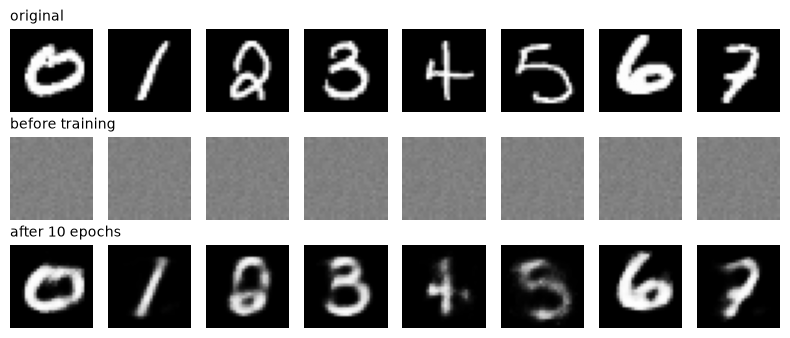

In [23]:
# ==================== [1-3]
print("[1-3]")  # 어느 섹션의 출력인지


# 학습 함수 (P2 빈칸 정답) · 학습 1만 장 · 128장씩
def train(model, epochs=10, loss_fn=F.mse_loss, seed=0):           # 모델을 받아 학습 후 돌려줌
    torch.manual_seed(seed)                                        # 섞는 순서 고정
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)            # 인코더 · 디코더 가중치 전부
    for epoch in range(epochs):                                    # 학습 이미지 전체를 epochs번
        model.train()                                              # 학습 모드
        perm = torch.randperm(len(Xtr), device=device)             # 번호 섞기
        for i in range(0, len(Xtr), 128):                          # 128장씩 묶음
            x = Xtr[perm[i:i + 128]]                               # 섞인 번호로 묶음 꺼내기
            opt.zero_grad()                                        # 앞 묶음 기울기 비우기
            loss = loss_fn(model(x), x)                            # 정답 자리에도 입력 x
            loss.backward()                                        # 기울기 계산
            opt.step()                                             # 가중치 갱신
        if epoch in (0, epochs // 2 - 1, epochs - 1):              # 1 · 중간 · 끝만
            print(f"  epoch {epoch + 1}  loss {loss.item():.4f}")  # 마지막 묶음의 loss
    return model                                                   # 학습된 모델


# 같은 seed로 시작 → 학습 전 ae0 · 학습 후 ae32
torch.manual_seed(0)                      # 학습 전 모델의 출발점
ae0 = AutoEncoder(32).to(device)          # 학습 안 함 (비교용)
torch.manual_seed(0)                      # 같은 출발점 → 차이는 학습 때문
ae32 = train(AutoEncoder(32).to(device))  # 5 epoch


# 같은 평가 1만 장으로 학습 전 · 후 비교
print(f"복원 MSE  학습 전 {mse(run(ae0, Xte)):.4f}"           # 같은 평가 1만 장으로
      f" → 학습 후 {mse(run(ae32, Xte)):.4f}")
show([("original", Xte), ("before training", run(ae0, Xte)),  # 원본 · 학습 전 · 학습 후 3줄
      ("after 10 epochs", run(ae32, Xte))])

[1-4]
  epoch 1  loss 0.0688


  epoch 5  loss 0.0645


  epoch 10  loss 0.0697


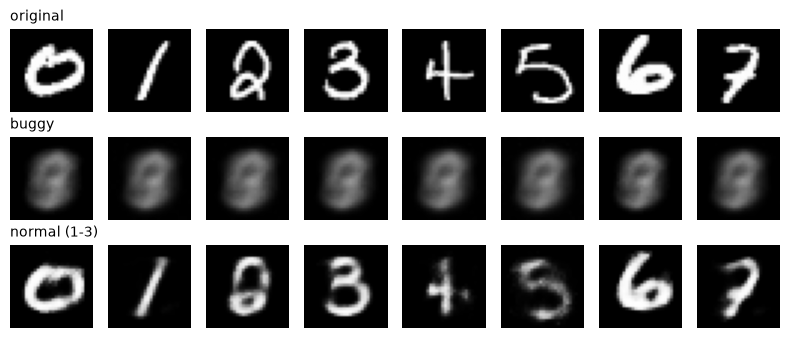

버그판  8장 사이 차이 0.008 | 복원 MSE 0.0681
정상판  8장 사이 차이 0.153 | 복원 MSE 0.0191


In [24]:
# ==================== [1-4]
print("[1-4]")  # 어느 섹션의 출력인지


# 버그판 학습 (P2_BUG와 같은 버그 · 조건은 1-3과 같게) · 에러 없이 끝남
def train_buggy(model, epochs=10, seed=0):                         # 1-3 train과 한 줄씩 비교할 대상
    torch.manual_seed(seed)                                        # 섞는 순서 고정
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)            # 1-3과 같음
    for epoch in range(epochs):                                    # 1-3과 같음
        model.train()                                              # 1-3과 같음
        perm = torch.randperm(len(Xtr), device=device)             # 입력용 번호 섞기
        other = torch.randperm(len(Xtr), device=device)            # 따로 섞은 번호
        for i in range(0, len(Xtr), 128):                          # 1-3과 같음
            x = Xtr[perm[i:i + 128]]                               # 입력 묶음
            y = Xtr[other[i:i + 128]]                              # x와 짝이 아닌 이미지
            opt.zero_grad()                                        # 1-3과 같음
            loss = F.mse_loss(model(x), y)                         # ← 버그: 정답이 y
            loss.backward()                                        # 1-3과 같음
            opt.step()                                             # 1-3과 같음
        if epoch in (0, epochs // 2 - 1, epochs - 1):              # 1 · 중간 · 끝만
            print(f"  epoch {epoch + 1}  loss {loss.item():.4f}")  # loss만 보면 이상한지 모름
    return model                                                   # 버그판 모델


# 1단계: 코드를 읽기 전에 실행하고 그림부터 봄
torch.manual_seed(0)                                                     # 1-3과 같은 출발점
bug = train_buggy(AutoEncoder(32).to(device))                            # 코드 읽기 전에 먼저 실행
out_bug, out_ok = run(bug, Xte), run(ae32, Xte)                          # 버그판 · 정상판 복원
show([("original", Xte), ("buggy", out_bug), ("normal (1-3)", out_ok)])  # 그림부터 비교


# 2단계: 8장이 서로 얼마나 다른가 (장끼리 차이 = 칸별 표준편차 평균)
for name, out in [("버그판", out_bug), ("정상판", out_ok)]:  # 두 모델을 같은 잣대로
    spread = out[SHOW].std(dim=0).mean().item()              # 8장끼리 얼마나 다른가
    # 0에 가까우면 모두 같은 그림
    print(f"{name}  8장 사이 차이 {spread:.3f} | 복원 MSE {mse(out):.4f}")

[2-1]
  epoch 1  loss 0.0365


  epoch 5  loss 0.0198


  epoch 10  loss 0.0125
Sigmoid 있음  범위 0.00 ~ 1.00 | 0~1 밖 0.0% | MSE 0.0191
Sigmoid 없음  범위 -0.63 ~ 1.56 | 0~1 밖 41.7% | MSE 0.0170
[2-2]
  epoch 1  loss 0.2491


  epoch 5  loss 0.1549


  epoch 10  loss 0.1029
MSE로 학습 → 복원 MSE 0.0191
BCE로 학습 → 복원 MSE 0.0187


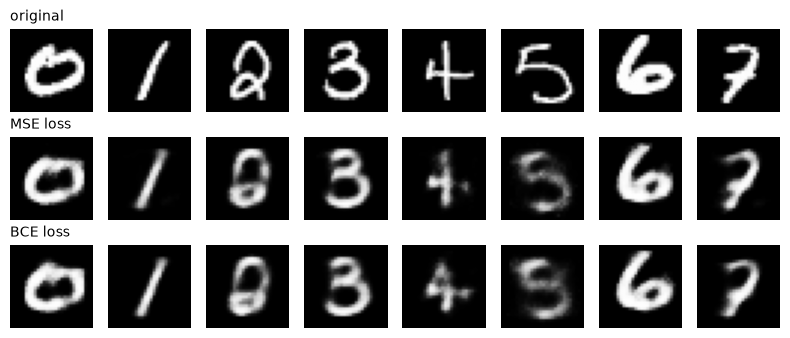

RuntimeError: all elements of input should be between 0 and 1


In [25]:
# ==================== [2-1]
print("[2-1]")  # 어느 섹션의 출력인지


# 마지막 Sigmoid를 뺀 디코더 (나머지는 같음)
class AENoSigmoid(AutoEncoder):           # 1-2 모델을 물려받아 한 곳만 바꿈
    def __init__(self, latent_dim=32):    # 부모와 같은 인자
        super().__init__(latent_dim)      # 부모 층을 그대로 만든 뒤
        self.decoder = self.decoder[:-1]  # Sigmoid만 떼어 냄


# 같은 조건으로 학습 (5 epoch · seed 0)
torch.manual_seed(0)                          # 1-3과 같은 출발점
ae_nosig = train(AENoSigmoid(32).to(device))  # 같은 조건 · 10 epoch


# 출력 범위 · 0~1 밖 비율 · 복원 MSE 비교
for name, m in [("Sigmoid 있음", ae32), ("Sigmoid 없음", ae_nosig)]:       # 두 모델 비교
    out = run(m, Xte)                                                      # 평가 1만 장 복원
    outside = ((out < 0) | (out > 1)).float().mean().item()                # 픽셀 범위 밖 비율
    print(f"{name}  범위 {out.min().item():.2f} ~ {out.max().item():.2f}"  # 최솟값 ~ 최댓값
          f" | 0~1 밖 {outside:.1%} | MSE {mse(out):.4f}")


# ==================== [2-2]
print("[2-2]")  # 어느 섹션의 출력인지


# 같은 모델 · 같은 seed · 손실만 BCE로 바꿔 학습
torch.manual_seed(0)                                                        # 1-3과 같은 출발점
ae_bce = train(AutoEncoder(32).to(device), loss_fn=F.binary_cross_entropy)  # 손실만 BCE


# 평가는 둘 다 같은 잣대(MSE)로
out_mse, out_bce = run(ae32, Xte), run(ae_bce, Xte)                      # 두 모델 복원
print(f"MSE로 학습 → 복원 MSE {mse(out_mse):.4f}")                       # 같은 잣대(평가 MSE)로
print(f"BCE로 학습 → 복원 MSE {mse(out_bce):.4f}")                       # 같은 잣대(평가 MSE)로
show([("original", Xte), ("MSE loss", out_mse), ("BCE loss", out_bce)])  # 그림도 비교


# BCE는 출력이 0~1이어야 함 → Sigmoid 없는 출력이면 에러
try:
    F.binary_cross_entropy(torch.tensor([1.3]), torch.tensor([1.0]))  # 1을 넘는 출력을 일부러
except RuntimeError as e:                                             # 에러를 잡아 멈추지 않게
    print("RuntimeError:", e)                                         # 에러 문장 그대로 읽기

[2-3]
잠재 벡터 모양 (10000, 32)
숫자 0 한 장 앞 5개: [-3.15  7.48 -5.85  7.05 -2.21]
픽셀 784  같은 숫자 8.56 | 다른 숫자 9.98 | 비율 1.17배
잠재 32  같은 숫자 16.55 | 다른 숫자 21.20 | 비율 1.28배


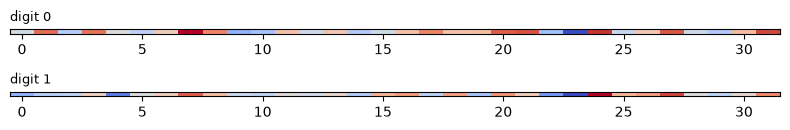

[2-4]
잠재   2 | 남는 값   0.3% | 파라미터 202,258
잠재   8 | 남는 값   1.0% | 파라미터 203,800
잠재  32 | 남는 값   4.1% | 파라미터 209,968
잠재 128 | 남는 값  16.3% | 파라미터 234,640
통로 앞뒤 두 층: 8352


In [26]:
# ==================== [2-3]
print("[2-3]")  # 어느 섹션의 출력인지


# 평가 1만 장을 인코더에만 통과 → 잠재 벡터
with torch.no_grad():                                           # 기울기 계산 끔 (꺼내기만)
    Z = torch.cat([ae32.encoder(Xte[i:i + 2000])                # 인코더만 통과 · 2,000장씩
                   for i in range(0, 10000, 2000)]).cpu()
print("잠재 벡터 모양", tuple(Z.shape))                         # (장 수, 32)
print("숫자 0 한 장 앞 5개:", Z[SHOW[0], :5].numpy().round(2))  # 평범한 숫자들


# 같은 숫자끼리 · 다른 숫자끼리 평균 거리 (라벨은 계산 뒤에만 씀)
def mean_dist(A, idx):                                    # 같은 숫자 · 다른 숫자 평균 거리
    D = torch.cdist(A[idx], A[idx])                       # 모든 짝의 거리
    same = (yte[idx][:, None] == yte[idx][None, :])       # 짝마다 라벨이 같은가
    return D[same].mean().item(), D[~same].mean().item()  # (같은, 다른) 평균


idx = torch.arange(2000)                                    # 앞 2,000장
P = Xte.flatten(1).cpu()                                    # 픽셀 784개
for name, A in [("픽셀 784", P), ("잠재 32", Z)]:           # 두 공간을 같은 방법으로
    s, d = mean_dist(A, idx)                                # 라벨은 계산 뒤 묶기에만
    print(f"{name}  같은 숫자 {s:.2f} | 다른 숫자 {d:.2f}"  # 비율이 클수록 잘 갈림
          f" | 비율 {d / s:.2f}배")


# 숫자 0 · 1의 잠재 벡터 32칸을 색 띠로
fig, axes = plt.subplots(2, 1, figsize=(8, 1.4))                    # 띠 두 줄
for ax, k in zip(axes, [SHOW[0], SHOW[1]]):                         # 숫자 0 · 1 한 장씩
    ax.imshow(Z[k][None], cmap="coolwarm", aspect="auto")           # 32칸을 색으로 (음수 파랑)
    ax.set_yticks([])                                               # 세로 눈금 숨김
    ax.set_title(f"digit {yte[k].item()}", loc="left", fontsize=9)  # 어느 숫자인지
plt.tight_layout()                                                  # 간격 정리
plt.show()                                                          # 그림 출력


# ==================== [2-4]
print("[2-4]")  # 어느 섹션의 출력인지


# 잠재 크기별 파라미터 수 (학습 없이 세기만)
for d in [2, 8, 32, 128]:                                            # 잠재 크기 네 가지
    n = sum(p.numel() for p in AutoEncoder(d).parameters())          # 가중치 개수 합
    print(f"잠재 {d:>3} | 남는 값 {d / 784:6.1%} | 파라미터 {n:,}")  # 압축률 · 파라미터


# 바뀌는 곳은 통로 앞뒤 두 층뿐: 128×d + d  +  d×128 + 128
d = 32                                                  # 1-3 모델 크기
print("통로 앞뒤 두 층:", 128 * d + d + d * 128 + 128)  # 바뀌는 두 층만 손계산

[2-5]


PCA 잠재 모양 (10000, 32)
PCA 32  복원 MSE 0.0170
AE  32  복원 MSE 0.0191
PCA 출력 범위 -0.67 ~ 1.53


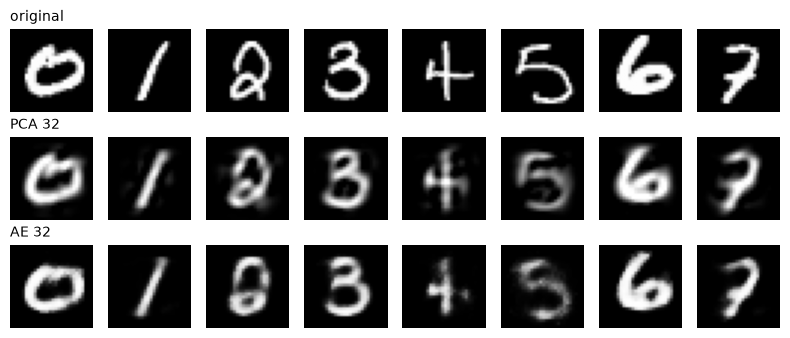

In [27]:
# ==================== [2-5]
print("[2-5]")  # 어느 섹션의 출력인지


# PCA: 학습 1만 장으로 주성분 32개 찾기 (선형 · 한 번에 계산)
Xtr_np = Xtr.flatten(1).cpu().numpy()                   # (10000, 784)
Xte_np = Xte.flatten(1).cpu().numpy()                   # sklearn은 넘파이 (장, 784)
pca = PCA(n_components=32, random_state=0).fit(Xtr_np)  # 학습 1만 장으로 축 32개


# 압축(transform) → 복원(inverse_transform) → 원래 모양
Zp = pca.transform(Xte_np)                                       # (10000, 32)
rec = pca.inverse_transform(Zp).reshape(-1, 1, 28, 28)           # 32개 → 784개 → 그림 모양
out_pca = torch.tensor(rec, dtype=torch.float32, device=device)  # mse()에 넣으려고 텐서로
print("PCA 잠재 모양", Zp.shape)                                 # AE 잠재와 같은 크기
print(f"PCA 32  복원 MSE {mse(out_pca):.4f}")                    # 같은 평가 1만 장
print(f"AE  32  복원 MSE {mse(run(ae32, Xte)):.4f}")             # 같은 평가 1만 장
print(f"PCA 출력 범위 {rec.min():.2f} ~ {rec.max():.2f}")        # 선형이라 0~1 밖도 나옴
show([("original", Xte), ("PCA 32", out_pca.clamp(0, 1)),        # 그릴 때만 0~1로 자름
      ("AE 32", run(ae32, Xte))])

In [28]:
# ==================== [3-1]
print("[3-1]")  # 어느 섹션의 출력인지


# 손계산 공식: (n + 2p - k) // s + 1  (CNN 크기 공식 · 이 노트북에서 1회)
def conv_out(n, k=3, s=2, p=1):      # 들어가는 크기 → 나오는 크기
    return (n + 2 * p - k) // s + 1  # // = 내림


# 공식 ↔ 실제 Conv2d 결과 대조
down = nn.Conv2d(1, 1, kernel_size=3, stride=2, padding=1)        # 확인용 층 하나
for n in [28, 14, 7, 30, 15]:                                     # 짝수 · 홀수 섞어서
    real = down(torch.zeros(1, 1, n, n)).shape[-1]                # 실제 통과시킨 크기
    kind = "짝수" if n % 2 == 0 else "홀수"                       # 짝 · 홀 표시
    print(f"{n:>2} ({kind}) → 공식 {conv_out(n)} | 실제 {real}")  # 공식 = 실제인지


# 채널: 필터 수 = 결과 판 수 (세로 · 가로와 따로 정함)
conv = nn.Conv2d(16, 32, 3, stride=2, padding=1)                           # 받는 판 16 · 필터 32
print("가중치 모양", tuple(conv.weight.shape))                             # (필터, 받는 판, 3, 3)
print("1×28×28 →", tuple(nn.Conv2d(1, 16, 3, 2, 1)(Xte[:1].cpu()).shape))  # 채널 1 → 16


# ==================== [3-2]
print("[3-2]")  # 어느 섹션의 출력인지


# 늘리는 공식: (n - 1) × s - 2p + k + op
def up_out(n, k=3, s=2, p=1, op=0):      # 늘리는 층의 크기 공식
    return (n - 1) * s - 2 * p + k + op  # 칸 + 틈 · op는 끝 한 칸


# 32×32 · 16채널을 세 방법으로 늘리기
t = torch.zeros(1, 16, 32, 32)                                  # 16채널 · 32×32
ways = {                                                        # 늘리는 방법 네 가지
    "ConvT k3 s2 p1": nn.ConvTranspose2d(16, 8, 3, 2, 1),
    "ConvT k3 s2 p1 op1": nn.ConvTranspose2d(16, 8, 3, 2, 1,
                                             output_padding=1),
    "ConvT k4 s2 p1": nn.ConvTranspose2d(16, 8, 4, 2, 1),
    "Upsample + Conv k3": nn.Sequential(
        nn.Upsample(scale_factor=2), nn.Conv2d(16, 8, 3, padding=1)),
}
for name, layer in ways.items():                                # 방법마다
    n = sum(p.numel() for p in layer.parameters())              # 가중치 개수
    print(f"{name:<20} → {layer(t).shape[-1]} | 파라미터 {n}")  # 나온 크기 · 가중치


# 공식과 대조
print("공식", up_out(32), up_out(32, op=1), up_out(32, k=4))  # 손계산과 대조


# 두 번 늘리면 모자람이 쌓임: 7 → 13 → 25 (op 없이)
print("op 없이 두 번:", 7, "→", up_out(7), "→", up_out(up_out(7)))  # 모자람이 쌓이는지

[3-1]
28 (짝수) → 공식 14 | 실제 14
14 (짝수) → 공식 7 | 실제 7
 7 (홀수) → 공식 4 | 실제 4
30 (짝수) → 공식 15 | 실제 15
15 (홀수) → 공식 8 | 실제 8
가중치 모양 (32, 16, 3, 3)
1×28×28 → (1, 16, 14, 14)
[3-2]
ConvT k3 s2 p1       → 63 | 파라미터 1160
ConvT k3 s2 p1 op1   → 64 | 파라미터 1160
ConvT k4 s2 p1       → 64 | 파라미터 2056
Upsample + Conv k3   → 64 | 파라미터 1160
공식 63 64 64
op 없이 두 번: 7 → 13 → 25


In [29]:
# ==================== [3-3]
print("[3-3]")  # 어느 섹션의 출력인지


# 층마다 나오는 크기를 모으는 도구 (P3 검사 도구를 줄인 것)
def trace(model, n=28):                                         # 층마다 나온 크기 목록
    h, sizes = torch.zeros(1, 1, n, n), []                      # 빈 이미지 한 장
    for layer in model:                                         # 층을 하나씩
        h = layer(h)                                            # 통과
        if isinstance(layer, (nn.Conv2d, nn.ConvTranspose2d)):  # 크기를 바꾸는 층만
            sizes.append(h.shape[-1])                           # 끝 숫자 = 가로 크기
    return sizes                                                # 예: [14, 7, 14, 28]


# 손계산 표 (P3 빈칸 정답) · 버그판 모델 (P3 원본)
table_ = [14, 7, 14, 28]                                  # 손계산 표 (P3 정답)
bad = nn.Sequential(                                      # P3 원본 모델
    nn.Conv2d(1, 8, 3, stride=2, padding=1), nn.ReLU(),
    nn.Conv2d(8, 16, 3, stride=2, padding=0), nn.ReLU(),  # ← 다른 곳
    nn.ConvTranspose2d(16, 8, 3, 2, 1, output_padding=1), nn.ReLU(),
    nn.ConvTranspose2d(8, 1, 3, 2, 1, output_padding=1), nn.Sigmoid())


# 표와 찍힌 크기를 층마다 대조 → 처음 다른 층 찾기
got = trace(bad)                                                            # 찍힌 크기
print("표   ", table_)                                                      # 손계산
print("버그판", got)                                                        # 실제
first = next(i for i, (a, b) in enumerate(zip(table_, got)) if a != b)      # 처음 다른 자리
print("처음 다른 층:", first + 1, "번째 →", type(bad[2 * first]).__name__)  # ReLU 건너 층 번호


# 그 층 설정 한 곳만 고침 (padding=0 → 1)
bad[2] = nn.Conv2d(8, 16, 3, stride=2, padding=1)                      # 그 층의 padding만 0 → 1
print("수정판", trace(bad), "→ 통과" if trace(bad) == table_ else "")  # 다시 대조

[3-3]
표    [14, 7, 14, 28]
버그판 [14, 6, 12, 24]
처음 다른 층: 2 번째 → Conv2d
수정판 [14, 7, 14, 28] → 통과


In [30]:
# ==================== [3-4]
print("[3-4]")  # 어느 섹션의 출력인지


# 줄이기 2번 · 늘리기 2번 작은 모델 (학습 없음 · 크기만 봄)
tiny = nn.Sequential(                               # 줄이기 2번 · 늘리기 2번
    nn.Conv2d(1, 8, 3, 2, 1), nn.ReLU(),            # k3 s2 p1 → 반
    nn.Conv2d(8, 16, 3, 2, 1), nn.ReLU(),
    nn.ConvTranspose2d(16, 8, 4, 2, 1), nn.ReLU(),  # k4 s2 p1 → 두 배
    nn.ConvTranspose2d(8, 1, 4, 2, 1))


# 크기 네 가지를 넣어 보기
for h, w in [(28, 28), (32, 32), (30, 30), (250, 536)]:                  # 크기 네 가지
    out = tiny(torch.zeros(1, 1, h, w))                                  # 빈 이미지 통과
    mark = "" if out.shape[-2:] == (h, w) else "  ← 크기 다름"           # 돌아왔는지 표시
    print(f"입력 {h}×{w} → 출력 {out.shape[-2]}×{out.shape[-1]}{mark}")  # 세로 × 가로


# 30×30이면 손실 계산(칸마다 빼기)에서 에러 (일부러 내는 에러)
x30 = torch.rand(1, 1, 30, 30)           # 30×30 한 장
try:
    ((tiny(x30) - x30) ** 2).mean()      # F.mse_loss 안의 계산과 같음
except RuntimeError as e:                # 에러를 잡아 멈추지 않게
    print("RuntimeError:", str(e)[:62])  # 앞부분만 읽기


# 가장 간단한 해결: 출력에서 원래 크기만 잘라내기
out = tiny(x30)[..., :30, :30]          # 아래 · 오른쪽 여분 제거
print("잘라낸 출력", tuple(out.shape),  # 30×30이 됐는지
      "| loss", round(F.mse_loss(out, x30).item(), 4))

[3-4]
입력 28×28 → 출력 28×28
입력 32×32 → 출력 32×32
입력 30×30 → 출력 32×32  ← 크기 다름
입력 250×536 → 출력 252×536  ← 크기 다름
RuntimeError: The size of tensor a (32) must match the size of tensor b (30)
잘라낸 출력 (1, 1, 30, 30) | loss 0.3306


[3-5]
Conv2d           (1, 16, 14, 14)
Conv2d           (1, 32, 7, 7)
ConvTranspose2d  (1, 16, 14, 14)
ConvTranspose2d  (1, 1, 28, 28)
가운데 값  AE 32 | ConvAE 1,568 (입력 784)
파라미터  AE 209,968 | ConvAE 9,569
실수 ① RuntimeError: have 16 channels, but got 32 channels instead
실수 ② 모양 (1, 1, 25, 25)


  epoch 1  loss 0.0263


  epoch 5  loss 0.0025


  epoch 10  loss 0.0011
복원 MSE  AE 32 0.0191 | ConvAE 0.0013


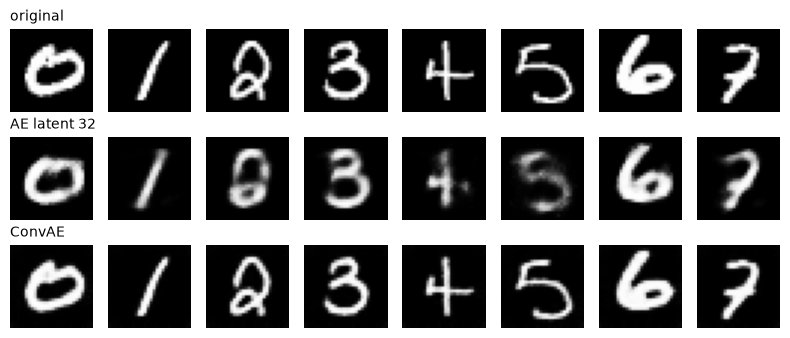

In [31]:
# ==================== [3-5]
print("[3-5]")  # 어느 섹션의 출력인지


# Conv 오토인코더 (P4 빈칸 정답)
class ConvAE(nn.Module):                                           # 이미지 모양 그대로 다루는 AE
    def __init__(self):                                            # 층 만들기
        super().__init__()                                         # 부모 초기화
        self.encoder = nn.Sequential(                              # 줄이는 쪽 (Conv2d)
            nn.Conv2d(1, 16, 3, stride=2, padding=1), nn.ReLU(),   # →16×14×14
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU())  # →32×7×7
        self.decoder = nn.Sequential(                              # 늘리는 쪽 (ConvTranspose2d)
            nn.ConvTranspose2d(32, 16, 3, stride=2, padding=1,
                               output_padding=1), nn.ReLU(),       # →16×14×14
            nn.ConvTranspose2d(16, 1, 3, stride=2, padding=1,
                               output_padding=1), nn.Sigmoid())    # →1×28×28

    def forward(self, x):                     # model(x)의 길
        return self.decoder(self.encoder(x))  # 펴지도 접지도 않음


# 한 장을 층마다 통과 → 설계 표와 대조
torch.manual_seed(0)                                          # 같은 시작 가중치
cae = ConvAE().to(device)                                     # 학습 전 모델 (모양 확인용)
h = Xte[:1]                                                   # 한 장
for layer in list(cae.encoder) + list(cae.decoder):           # 층을 하나씩
    h = layer(h)                                              # 통과
    if not isinstance(layer, (nn.ReLU, nn.Sigmoid)):          # 모양을 바꾸는 층만 출력
        print(f"{type(layer).__name__:<16}", tuple(h.shape))  # 설계 표와 대조


# 가운데 값 개수 · 파라미터 수 비교
n_cae = sum(p.numel() for p in cae.parameters())               # ConvAE 가중치 개수
n_ae = sum(p.numel() for p in ae32.parameters())               # Dense AE 가중치 개수
print(f"가운데 값  AE 32 | ConvAE {32 * 7 * 7:,} (입력 784)")  # 통로 넓이 비교
print(f"파라미터  AE {n_ae:,} | ConvAE {n_cae:,}")             # 파라미터 비교


# 흔한 실수 ①: 받는 채널을 틀림 → 바로 에러
try:
    nn.ConvTranspose2d(16, 16, 3, 2, 1, output_padding=1)(  # 받는 채널을 16으로 틀림
        torch.zeros(1, 32, 7, 7))
except RuntimeError as e:                                   # 채널 에러를 잡음
    print("실수 ① RuntimeError:", str(e)[-45:])             # 끝부분 = 무엇이 다른지


# 흔한 실수 ②: output_padding 빠뜨림 → 에러 없이 크기만 틀림
miss = nn.Sequential(nn.ConvTranspose2d(32, 16, 3, 2, 1),          # output_padding을 뺀 디코더
                     nn.ConvTranspose2d(16, 1, 3, 2, 1))
print("실수 ② 모양", tuple(miss(torch.zeros(1, 32, 7, 7)).shape))  # 에러 없이 크기만 틀림


# 같은 조건(학습 1만 장 · 5 epoch · seed 0)으로 학습 → 비교
torch.manual_seed(0)                                        # 1-3과 같은 출발점
cae = train(ConvAE().to(device))                            # 1-3 train · 같은 조건
out_cae = run(cae, Xte)                                     # 평가 1만 장 복원
print(f"복원 MSE  AE 32 {mse(run(ae32, Xte)):.4f} | ConvAE {mse(out_cae):.4f}")  # 같은 잣대
show([("original", Xte), ("AE latent 32", run(ae32, Xte)),  # 그림 3줄
      ("ConvAE", out_cae)])

[4-1]
잠재 2 학습
  epoch 1  loss 0.0629


  epoch 5  loss 0.0560


  epoch 10  loss 0.0401
잠재 8 학습
  epoch 1  loss 0.0640


  epoch 5  loss 0.0328


  epoch 10  loss 0.0207
잠재  2 | 복원 MSE 0.0512
잠재  8 | 복원 MSE 0.0279
잠재 32 | 복원 MSE 0.0191


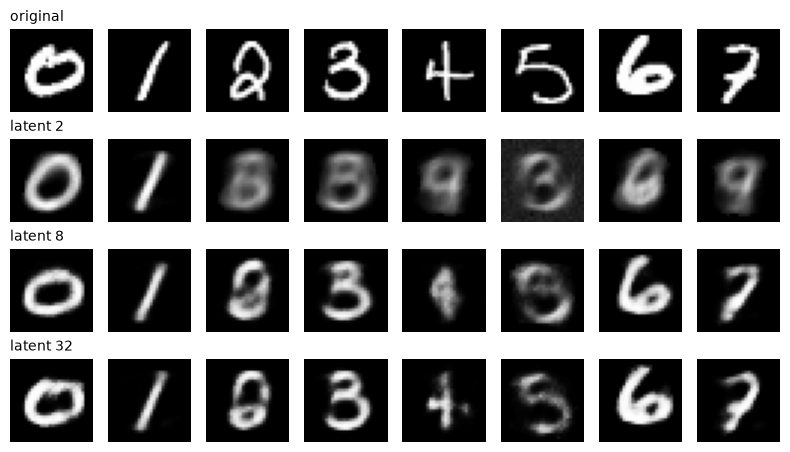

In [32]:
# ==================== [4-1]
print("[4-1]")  # 어느 섹션의 출력인지


# 잠재 2 · 8 학습 (32는 1-3 모델 그대로 · 모두 같은 조건)
models = {32: ae32}                               # 32는 1-3 모델 재사용
for d in [2, 8]:                                  # 새로 학습할 두 크기
    print(f"잠재 {d} 학습")                       # 어느 모델의 loss인지
    torch.manual_seed(0)                          # 모두 같은 출발점
    models[d] = train(AutoEncoder(d).to(device))  # 같은 조건 · 10 epoch


# 같은 평가 1만 장 · 같은 계산으로 복원 오차 비교
outs = {d: run(models[d], Xte) for d in [2, 8, 32]}                         # 세 모델 복원
for d in [2, 8, 32]:                                                        # 크기 순서로
    print(f"잠재 {d:>2} | 복원 MSE {mse(outs[d]):.4f}")                     # 같은 평가 1만 장
show([("original", Xte)] + [(f"latent {d}", outs[d]) for d in [2, 8, 32]])  # 원본 + 3줄

[4-2]
잠재 좌표 모양 (10000, 2)


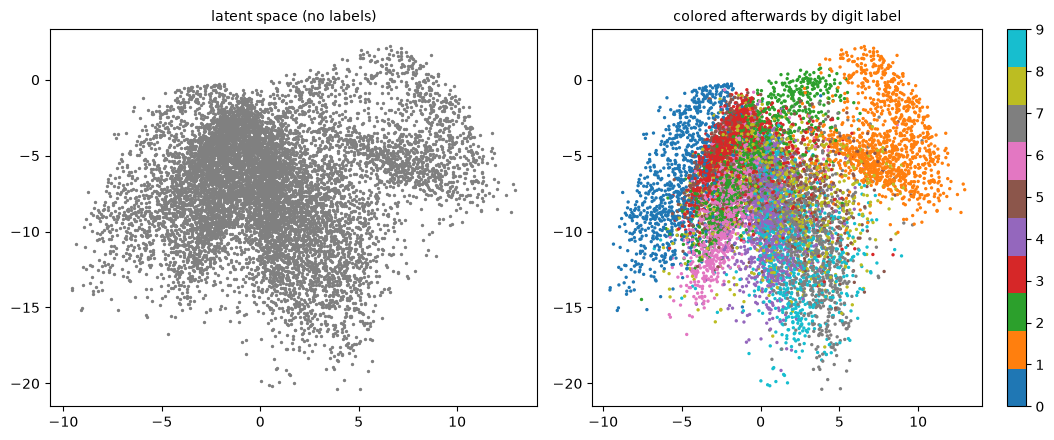

숫자 0 중심 (  -4.9,   -6.5)  숫자 1 중심 (   7.7,   -4.0)
숫자 2 중심 (  -0.5,   -5.3)  숫자 3 중심 (  -1.4,   -4.6)
숫자 4 중심 (   0.5,   -9.0)  숫자 5 중심 (  -0.2,   -6.2)
숫자 6 중심 (  -2.0,   -8.3)  숫자 7 중심 (   2.8,  -10.1)
숫자 8 중심 (   0.9,   -7.2)  숫자 9 중심 (   1.6,  -10.4)
찍힌 범위  x -9.6 ~ 13.0 | y -20.4 ~ 2.2


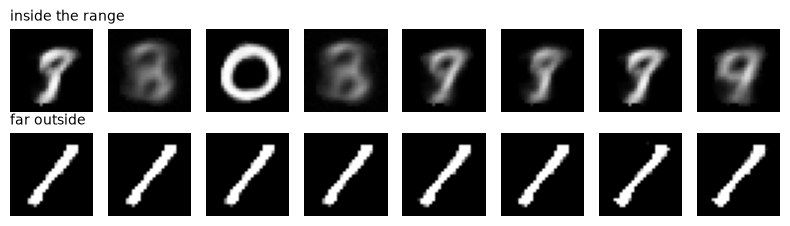

In [33]:
# ==================== [4-2]
print("[4-2]")  # 어느 섹션의 출력인지


# 잠재 2 모델: 평가 1만 장 → 점 1만 개 (x, y)
with torch.no_grad():                                   # 꺼내기만 (기울기 끔)
    Z2 = torch.cat([models[2].encoder(Xte[i:i + 2000])  # 잠재 2 인코더만 통과
                    for i in range(0, 10000, 2000)]).cpu()
print("잠재 좌표 모양", tuple(Z2.shape))                # (장 수, 2) = 점 1만 개


# 왼쪽: 라벨 없이 회색 / 오른쪽: 학습이 끝난 뒤 라벨로 색만 입힘
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))                    # 왼쪽 회색 · 오른쪽 색칠
axes[0].scatter(Z2[:, 0], Z2[:, 1], s=2, c="gray")                   # 라벨 없이 점만
axes[0].set_title("latent space (no labels)", fontsize=10)           # 왼쪽 제목
sc = axes[1].scatter(Z2[:, 0], Z2[:, 1], s=2, c=yte, cmap="tab10")   # 같은 점에 라벨 색만
axes[1].set_title("colored afterwards by digit label", fontsize=10)  # 학습 뒤 색칠
plt.colorbar(sc, ax=axes[1], ticks=range(10))                        # 색 ↔ 숫자 짝
plt.tight_layout()                                                   # 간격 정리
plt.show()                                                           # 그림 출력


# 숫자별 중심 좌표 (색칠과 같은 정보를 숫자로)
for k in range(0, 10, 2):                                  # 두 숫자씩 한 줄
    a, b = Z2[yte == k].mean(0), Z2[yte == k + 1].mean(0)  # 숫자별 평균 좌표
    print(f"숫자 {k} 중심 ({a[0]:6.1f}, {a[1]:6.1f})  "    # 그림을 숫자로
          f"숫자 {k + 1} 중심 ({b[0]:6.1f}, {b[1]:6.1f})")


# 찍힌 범위 안 · 범위 밖 멀리에서 좌표를 뽑아 디코더에 넣기
torch.manual_seed(1)                                                # 뽑는 좌표 고정
lo, hi = Z2.min(0).values, Z2.max(0).values                         # 축마다 최솟값 · 최댓값
span = hi - lo                                                      # 찍힌 범위의 폭
inside = lo + span * torch.rand(8, 2)                               # 범위 상자 안
outside = hi + span * (0.5 + torch.rand(8, 2))                      # 상자 밖 오른쪽 위
print(f"찍힌 범위  x {lo[0]:.1f} ~ {hi[0]:.1f} | y {lo[1]:.1f} ~ {hi[1]:.1f}")  # 상자 범위
with torch.no_grad():                                               # 생성만 (기울기 끔)
    dec = models[2].decoder                                         # 디코더만 사용
    gen_in = dec(inside.to(device)).reshape(-1, 1, 28, 28).cpu()    # 상자 안 좌표 → 그림
    gen_out = dec(outside.to(device)).reshape(-1, 1, 28, 28).cpu()  # 멀리 밖 좌표 → 그림
fig, axes = plt.subplots(2, 8, figsize=(8, 2.3))                    # 2줄 × 8칸
for c in range(8):                                                  # 칸마다
    for r, G in enumerate([gen_in, gen_out]):                       # 윗줄 안 · 아랫줄 밖
        axes[r, c].imshow(G[c, 0], cmap="gray", vmin=0, vmax=1)     # 밝기 0~1 고정
        axes[r, c].axis("off")                                      # 눈금 숨김
axes[0, 0].set_title("inside the range", loc="left", fontsize=10)   # 윗줄 이름
axes[1, 0].set_title("far outside", loc="left", fontsize=10)        # 아랫줄 이름
plt.tight_layout()                                                  # 간격 정리
plt.show()                                                          # 그림 출력